# Práctica 4 · Ensambles: deserción estudiantil y Bank Marketing

**Materia:** Introducción a la Ciencia de Datos 2026

**Pregunta:** ¿cuánto ganan los ensambles sobre los cinco clasificadores base de la Práctica 3 cuando estos ya están bien ajustados? Se usa el mismo conjunto de deserción estudiantil, con los mismos cinco pliegues estratificados. Los cinco clasificadores base (árbol de decisión, Naive Bayes, kNN, SVM y regresión logística) se recuperan con el preprocesamiento y los hiperparámetros que resultaron mejores en la Práctica 3, sin repetir su optimización. Después se busca el mejor modelo para un segundo conjunto, Bank Marketing.

> Se utilizó el asistente de inteligencia artificial Claude (Anthropic) en la elaboración de este notebook. La autora revisó el contenido y es responsable de su exactitud.

### Contenido
**Parte 1 · Deserción estudiantil**
1. Configuración y versiones
2. Datos, pliegues y protocolo de evaluación
3. Los cinco clasificadores base de la Práctica 3
4. Varianza: árbol sin poda y *bagging*
5. Sesgo: tocón y AdaBoost
6. Combinar los cinco base: votación dura, votación suave y *stacking*
7. *Bagging* optimizado: Random Forest y Extra-Trees
8. *Boosting* optimizado: XGBoost y LightGBM
9. Tabla comparativa y matriz de confusión del mejor modelo

**Parte 2 · Bank Marketing**

10. Datos y protocolo
11. Modelos probados
12. Tabla, matriz de confusión y guardado del mejor modelo
13. ¿Funcionó lo mismo que en la deserción?

**14. Conclusiones**

## 1. Configuración y versiones

Todas las fuentes de aleatoriedad usan semillas fijas: `SEMILLA = 42` en la deserción (la misma de la Práctica 3, de la que dependen los pliegues) y `SEMILLA_BANCO = 2026` en Bank Marketing (la que fija el enunciado). Las rutas son relativas a la raíz del repositorio.

In [1]:
import time, platform, warnings, re
import importlib.metadata as metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import joblib
from scipy.stats import loguniform, randint, uniform

from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, KBinsDiscretizer, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (StratifiedKFold, cross_validate, cross_val_predict,
                                     RandomizedSearchCV, TunedThresholdClassifierCV)
from sklearn.metrics import f1_score, recall_score, confusion_matrix, make_scorer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import (BaggingClassifier, AdaBoostClassifier, VotingClassifier, StackingClassifier,
                              RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier)
import xgboost
import lightgbm
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEMILLA = 42            # Práctica 3: pliegues, búsquedas y modelos de la deserción
SEMILLA_BANCO = 2026    # enunciado: pliegues de Bank Marketing
np.random.seed(SEMILLA)

DIR_DATOS = Path("datos")
RUTA_DESERCION = DIR_DATOS / "desercion-entrenamiento.csv"
RUTA_BANCO = DIR_DATOS / "bank-additional-full.csv"
ESTUDIANTE = "marey-lugo"          # prefijo del archivo .joblib de entrega

N_JOBS = -1   # todos los núcleos disponibles; los modelos internos usan 1 núcleo para no competir

warnings.filterwarnings("ignore", message="Bins whose width are too small")
warnings.filterwarnings("ignore", message="X does not have valid feature names")
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

def version(paquete, modulo=None):
    try:
        return metadata.version(paquete)
    except metadata.PackageNotFoundError:
        return getattr(modulo, "__version__", "desconocida")

versiones = {
    "Python": platform.python_version(),
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__, "joblib": joblib.__version__,
    "xgboost": version("xgboost", xgboost), "lightgbm": version("lightgbm", lightgbm),
}
pd.Series(versiones, name="versión").to_frame()

,versión
Python,3.13.18
numpy,2.5.3
pandas,3.0.5
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
joblib,1.6.0
xgboost,3.0.5
lightgbm,4.6.0


Estilo de las gráficas y colores fijos: uno por clase (los mismos de la Práctica 3) y uno por familia de modelos.

In [2]:
CLASES = ["dropout", "enrolled", "graduate"]
NOMBRES_CLASE = {"dropout": "Desertor", "enrolled": "Inscrito", "graduate": "Graduado"}
COLOR_FAMILIA = {"base": "#8a8980", "individual": "#c3c2b7", "bagging": "#2a78d6",
                 "boosting": "#eb6834", "combinación": "#1baf7a", "referencia": "#d9d8d0"}

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3dd", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 2. Datos, pliegues y protocolo de evaluación

El conjunto es el de la Práctica 3: 3539 estudiantes del Instituto Politécnico de Portalegre con su situación al final de la duración normal de la carrera (`dropout`, `enrolled`, `graduate`). Como en la Práctica 3, la predicción se hace **al cierre del primer semestre**, así que se usan solo los **30 atributos** que se conocen en ese momento (los del segundo semestre quedan fuera). Los grupos de atributos y su codificación son los mismos de la Práctica 3.

In [3]:
desercion = pd.read_csv(RUTA_DESERCION)
desercion["Target"] = desercion["Target"].str.lower()

NOMINALES = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
             "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
BINARIAS = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
            "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
ORDINALES = ["Application order"]
NUMERICAS = ["Previous qualification (grade)", "Admission grade", "Age at enrollment",
             "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
             "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
             "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
             "Unemployment rate", "Inflation rate", "GDP"]
ATRIBUTOS = NOMINALES + BINARIAS + ORDINALES + NUMERICAS
assert len(ATRIBUTOS) == 30

X = desercion[ATRIBUTOS]
y = desercion["Target"]
print(f"{X.shape[0]} estudiantes × {X.shape[1]} atributos")
y.value_counts().reindex(CLASES).to_frame("estudiantes").assign(
    proporción=lambda d: (d["estudiantes"] / d["estudiantes"].sum()).round(3))

3539 estudiantes × 30 atributos


,estudiantes,proporción
Target,,
dropout,1137,0.321
enrolled,635,0.179
graduate,1767,0.499


**Los mismos cinco pliegues.** `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` sobre los mismos 3539 estudiantes produce exactamente las particiones de la Práctica 3; se materializan una vez en `PLIEGUES` y ese mismo objeto se pasa a todas las evaluaciones y búsquedas.

**Una sola función de evaluación.** Todo modelo se evalúa con `cross_validate` sobre `PLIEGUES` y dos métricas: el **F1 macro** (la métrica principal, igual peso a las tres clases) y la **sensibilidad de `enrolled`**, la clase más difícil. El tiempo de entrenamiento es el promedio, entre los cinco pliegues, de lo que tarda en ajustarse el modelo completo con 4/5 de los datos (para los ensambles incluye el ajuste de todos sus miembros y, en *stacking*, la validación cruzada interna). Todo lo que se ajusta con datos (codificadores, escaladores, calibración, meta-modelo) está dentro del modelo, de modo que en cada pliegue se ajusta solo con la parte de entrenamiento.

In [4]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
PLIEGUES = list(CV.split(X, y))
CV_INTERNA = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)   # calibración y stacking

SENS_ENROLLED = make_scorer(recall_score, labels=["enrolled"], average="macro")
METRICAS = {"f1_macro": "f1_macro", "sens_enrolled": SENS_ENROLLED}

RESULTADOS = {}   # nombre -> F1 por pliegue, sensibilidad, tiempo, familia, configuración, modelo

def registrar(nombre, familia, f1, sens, t_fit, modelo, config="—", t_busqueda=np.nan, n_config=np.nan):
    RESULTADOS[nombre] = {"familia": familia, "f1": np.asarray(f1), "sens": np.asarray(sens),
                          "t_fit": t_fit, "modelo": modelo, "config": config,
                          "t_busqueda": t_busqueda, "n_config": n_config}
    print(f"{nombre}: F1 macro = {np.mean(f1):.4f} ± {np.std(f1, ddof=1):.4f} · "
          f"sens. enrolled = {np.mean(sens):.3f} · entrenamiento {t_fit:.2f} s por pliegue")

def evaluar(nombre, modelo, familia, config="—", n_jobs=N_JOBS):
    r = cross_validate(modelo, X, y, cv=PLIEGUES, scoring=METRICAS, n_jobs=n_jobs)
    registrar(nombre, familia, r["test_f1_macro"], r["test_sens_enrolled"], r["fit_time"].mean(), modelo, config)
    return r

## 3. Los cinco clasificadores base de la Práctica 3

Se reconstruyen tal cual: mismo preprocesamiento y mejor configuración de cada búsqueda. Los valores continuos se escriben con todas sus cifras (se obtuvieron regenerando, con la misma semilla, las configuraciones que muestreó `RandomizedSearchCV` en la Práctica 3), así que **no se repite ninguna optimización**.

| Clasificador | Preprocesamiento | Mejor configuración (Práctica 3) | F1 macro P3 |
|---|---|---|---|
| Árbol de decisión | nominales *one-hot*, resto sin cambio | `log_loss`, profundidad 7, `min_samples_leaf` 44, `ccp_alpha` 5.8·10⁻⁵, `balanced` | 0.648 |
| Naive Bayes | nominales como categorías, numéricos en 4 intervalos por cuantiles | categórico, `alpha` = 0.0012 | 0.627 |
| kNN | nominales *one-hot*, numéricos estandarizados | k = 8, Manhattan, votos uniformes | 0.574 |
| SVM | igual que kNN | polinomial grado 3, `coef0` 1, `C` 62.5, `gamma` 0.0011, `balanced` | 0.682 |
| Regresión logística | igual que kNN | *elastic net* (`l1_ratio` 0.44), `C` 0.137, `balanced` | 0.680 |

En todos, los niveles nominales con menos de 10 estudiantes se agrupan en una categoría "infrecuente", que también recibe los códigos no vistos.

In [5]:
MIN_FREC = 10

def codificador_onehot():
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_FREC, sparse_output=False)

class CodificadorCategorico(BaseEstimator, TransformerMixin):
    # Cada nominal como entero 0..K-1 para CategoricalNB, con la misma agrupación de niveles raros (Práctica 3)
    def __init__(self, min_frequency=MIN_FREC):
        self.min_frequency = min_frequency

    def fit(self, X, y=None):
        self.ohe_ = OneHotEncoder(handle_unknown="infrequent_if_exist",
                                  min_frequency=self.min_frequency, sparse_output=False).fit(X)
        infrec = self.ohe_.infrequent_categories_
        self.n_cols_ = [len(cats) - (0 if inf is None else len(inf) - 1)
                        for cats, inf in zip(self.ohe_.categories_, infrec)]
        return self

    def transform(self, X):
        Z = self.ohe_.transform(X)
        salida, ini = [], 0
        for k in self.n_cols_:
            salida.append(Z[:, ini:ini + k].argmax(axis=1))
            ini += k
        return np.column_stack(salida).astype(int)

def prep_arbol():
    # árboles y ensambles de árboles: one-hot en nominales, todo lo demás sin cambio
    return ColumnTransformer([("nom", codificador_onehot(), NOMINALES),
                              ("resto", "passthrough", BINARIAS + ORDINALES + NUMERICAS)])

def prep_distancias():
    # kNN, SVM y regresión logística: one-hot en nominales y numéricos estandarizados
    return ColumnTransformer([("nom", codificador_onehot(), NOMINALES),
                              ("bin", "passthrough", BINARIAS),
                              ("num", StandardScaler(), ORDINALES + NUMERICAS)])

def prep_nb_categorico(n_bins):
    return ColumnTransformer([("nom", CodificadorCategorico(), NOMINALES),
                              ("bin", "passthrough", BINARIAS),
                              ("num", KBinsDiscretizer(n_bins=n_bins, encode="ordinal", strategy="quantile"),
                               ORDINALES + NUMERICAS)])

VERSION_SK = tuple(int(v) for v in sklearn.__version__.split(".")[:2])
def regresion_logistica(**kw):
    extra = {} if VERSION_SK >= (1, 8) else {"penalty": "elasticnet"}
    return LogisticRegression(solver="saga", max_iter=3000, tol=1e-3, random_state=SEMILLA, **extra, **kw)

BASE = {
    "Árbol de decisión": Pipeline([("prep", prep_arbol()), ("clf", DecisionTreeClassifier(
        criterion="log_loss", max_depth=7, min_samples_leaf=44, ccp_alpha=5.7834561109845845e-05,
        class_weight="balanced", random_state=SEMILLA))]),
    "Naive Bayes": Pipeline([("prep", prep_nb_categorico(4)), ("clf", CategoricalNB(alpha=0.0012087541473056963))]),
    "kNN": Pipeline([("prep", prep_distancias()), ("clf", KNeighborsClassifier(
        n_neighbors=8, weights="uniform", metric="minkowski", p=1))]),
    "SVM": Pipeline([("prep", prep_distancias()), ("clf", SVC(
        kernel="poly", degree=3, coef0=1.0, C=62.451395747430766, gamma=0.0010970529245749178,
        class_weight="balanced", cache_size=1000, random_state=SEMILLA))]),
    "Regresión logística": Pipeline([("prep", prep_distancias()), ("clf", regresion_logistica(
        C=0.137310924682403, l1_ratio=0.4393365018657701, class_weight="balanced"))]),
}
F1_P3 = {"Árbol de decisión": 0.6483, "Naive Bayes": 0.6274, "kNN": 0.5740, "SVM": 0.6823, "Regresión logística": 0.6801}

for nombre, modelo in BASE.items():
    evaluar(nombre, modelo, "base")

pd.DataFrame({"F1 macro (Práctica 3)": F1_P3,
              "F1 macro (aquí)": {n: RESULTADOS[n]["f1"].mean() for n in BASE}}).round(4)

Árbol de decisión: F1 macro = 0.6483 ± 0.0141 · sens. enrolled = 0.595 · entrenamiento 0.05 s por pliegue
Naive Bayes: F1 macro = 0.6274 ± 0.0147 · sens. enrolled = 0.402 · entrenamiento 0.03 s por pliegue
kNN: F1 macro = 0.5740 ± 0.0183 · sens. enrolled = 0.216 · entrenamiento 0.02 s por pliegue
SVM: F1 macro = 0.6823 ± 0.0103 · sens. enrolled = 0.603 · entrenamiento 0.48 s por pliegue
Regresión logística: F1 macro = 0.6801 ± 0.0103 · sens. enrolled = 0.570 · entrenamiento 0.39 s por pliegue


,F1 macro (Práctica 3),F1 macro (aquí)
Árbol de decisión,0.6483,0.6483
Naive Bayes,0.6274,0.6274
kNN,0.5740,0.5740
SVM,0.6823,0.6823
Regresión logística,0.6801,0.6801


Los cinco reproducen el F1 macro de la Práctica 3 (a cuatro decimales), lo que confirma que los pliegues, el preprocesamiento y los hiperparámetros son los mismos. La referencia que hay que superar es el **SVM, con 0.682**.

## 4. Varianza: árbol sin límite de profundidad y *bagging*

Un árbol sin límite de profundidad crece hasta que cada hoja es pura: sesgo casi nulo (en entrenamiento acierta todo) y **varianza alta** (pequeños cambios en los datos cambian mucho el árbol). *Bagging* entrena muchos árboles así, cada uno sobre una muestra *bootstrap* del entrenamiento, y vota. Para ver la curva contra el número de árboles se usa `warm_start=True`: en cada pliegue el mismo `BaggingClassifier` se reajusta con más árboles y solo entrena los nuevos.

In [6]:
evaluar("Árbol sin límite de profundidad",
        Pipeline([("prep", prep_arbol()), ("clf", DecisionTreeClassifier(random_state=SEMILLA))]), "individual")

N_ARBOLES = [1, 5, 10, 20, 50, 100, 200, 300, 400]
f1_bag_val = np.zeros((len(PLIEGUES), len(N_ARBOLES)))
f1_bag_ent = np.zeros_like(f1_bag_val)
sens_bag = np.zeros(len(PLIEGUES))
t_bag = np.zeros(len(PLIEGUES))

for k, (ent, val) in enumerate(PLIEGUES):
    bag = Pipeline([("prep", prep_arbol()), ("clf", BaggingClassifier(
        DecisionTreeClassifier(), n_estimators=1, warm_start=True, random_state=SEMILLA, n_jobs=N_JOBS))])
    for j, n in enumerate(N_ARBOLES):
        bag.set_params(clf__n_estimators=n)
        t0 = time.perf_counter()
        bag.fit(X.iloc[ent], y.iloc[ent])
        t_bag[k] += time.perf_counter() - t0          # tiempo acumulado = entrenar n árboles
        p_val = bag.predict(X.iloc[val])
        f1_bag_val[k, j] = f1_score(y.iloc[val], p_val, average="macro")
        f1_bag_ent[k, j] = f1_score(y.iloc[ent], bag.predict(X.iloc[ent]), average="macro")
    sens_bag[k] = recall_score(y.iloc[val], p_val, labels=["enrolled"], average="macro")

registrar(f"Bagging ({N_ARBOLES[-1]} árboles sin límite)", "bagging", f1_bag_val[:, -1], sens_bag, t_bag.mean(),
          Pipeline([("prep", prep_arbol()), ("clf", BaggingClassifier(
              DecisionTreeClassifier(), n_estimators=N_ARBOLES[-1], random_state=SEMILLA, n_jobs=N_JOBS))]))

pd.DataFrame({"F1 macro validación": f1_bag_val.mean(0), "desv. est.": f1_bag_val.std(0, ddof=1),
              "F1 macro entrenamiento": f1_bag_ent.mean(0)},
             index=pd.Index(N_ARBOLES, name="árboles")).round(4)

Árbol sin límite de profundidad: F1 macro = 0.5821 ± 0.0088 · sens. enrolled = 0.362 · entrenamiento 0.04 s por pliegue
Bagging (400 árboles sin límite): F1 macro = 0.6629 ± 0.0228 · sens. enrolled = 0.335 · entrenamiento 5.86 s por pliegue


,F1 macro validación,desv. est.,F1 macro entrenamiento
árboles,,,
1,0.5667,0.0214,0.8420
5,0.6226,0.0094,0.9579
10,0.6381,0.0198,0.9847
20,0.6464,0.0058,0.9963
50,0.6506,0.0126,0.9996
100,0.6551,0.0153,1.0000
200,0.6582,0.0221,1.0000
300,0.6639,0.0264,1.0000
400,0.6629,0.0228,1.0000


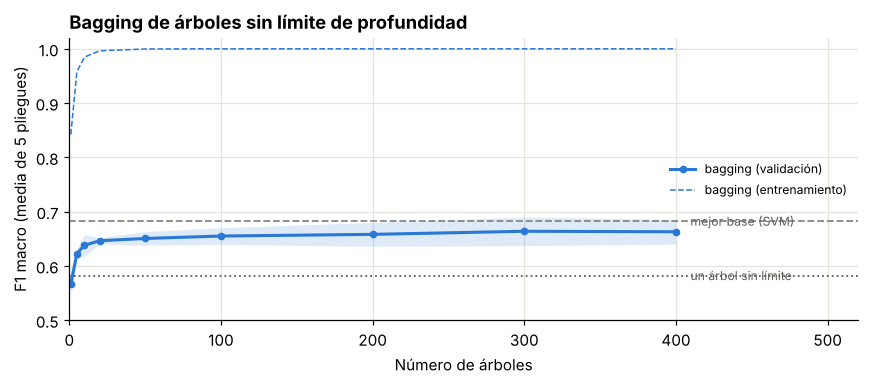

In [7]:
arbol_libre = RESULTADOS["Árbol sin límite de profundidad"]["f1"]
fig, ax = plt.subplots(figsize=(8, 3.6))
m, s = f1_bag_val.mean(0), f1_bag_val.std(0, ddof=1)
ax.fill_between(N_ARBOLES, m - s, m + s, color=COLOR_FAMILIA["bagging"], alpha=0.15, linewidth=0)
ax.plot(N_ARBOLES, m, "o-", color=COLOR_FAMILIA["bagging"], linewidth=2, markersize=4, label="bagging (validación)")
ax.plot(N_ARBOLES, f1_bag_ent.mean(0), "--", color=COLOR_FAMILIA["bagging"], linewidth=1, label="bagging (entrenamiento)")
ax.axhline(arbol_libre.mean(), color="#5f5e5a", linewidth=1.2, linestyle=":")
ax.text(405, arbol_libre.mean(), "  un árbol sin límite", va="center", fontsize=8, color="#5f5e5a")
ax.axhline(RESULTADOS["SVM"]["f1"].mean(), color=COLOR_FAMILIA["base"], linewidth=1.2, linestyle="--")
ax.text(405, RESULTADOS["SVM"]["f1"].mean(), "  mejor base (SVM)", va="center", fontsize=8, color="#5f5e5a")
ax.set_xlim(0, 520)
ax.set_xlabel("Número de árboles")
ax.set_ylabel("F1 macro (media de 5 pliegues)")
ax.set_ylim(0.5, 1.02)
ax.legend(loc="center right", fontsize=8, frameon=False)
ax.set_title("Bagging de árboles sin límite de profundidad")
plt.tight_layout()
plt.show()

La curva muestra *qué* mejora, pero no *por qué*. Para medir la varianza directamente se entrenan diez réplicas de cada modelo, cada una sobre una muestra *bootstrap* distinta del entrenamiento del pliegue 1 (diez "conjuntos de entrenamiento alternativos"), y se mide con qué frecuencia dos réplicas predicen clases distintas para el mismo estudiante de validación. Ese **desacuerdo entre réplicas** es una medida directa de la varianza: un modelo sin varianza daría siempre la misma predicción.

In [8]:
ent, val = PLIEGUES[0]
rng = np.random.default_rng(SEMILLA)
N_REPLICAS = 10
muestras = [rng.choice(ent, size=len(ent), replace=True) for _ in range(N_REPLICAS)]

def desacuerdo(predicciones):
    P = np.array(predicciones)                      # réplicas × estudiantes
    pares = [(a, b) for a in range(len(P)) for b in range(a + 1, len(P))]
    return np.mean([(P[a] != P[b]).mean() for a, b in pares])

filas = []
for n in [1, 10, 50, 100]:
    preds, f1s = [], []
    for r, idx in enumerate(muestras):
        clf = DecisionTreeClassifier(random_state=r) if n == 1 else BaggingClassifier(
            DecisionTreeClassifier(), n_estimators=n, random_state=r, n_jobs=N_JOBS)
        m_r = Pipeline([("prep", prep_arbol()), ("clf", clf)]).fit(X.iloc[idx], y.iloc[idx])
        p = m_r.predict(X.iloc[val])
        preds.append(p)
        f1s.append(f1_score(y.iloc[val], p, average="macro"))
    filas.append({"modelo": "árbol sin límite" if n == 1 else f"bagging de {n} árboles",
                  "desacuerdo entre réplicas": desacuerdo(preds), "F1 macro medio de las réplicas": np.mean(f1s)})
tabla_varianza = pd.DataFrame(filas).set_index("modelo")
tabla_varianza.round(3)

,desacuerdo entre réplicas,F1 macro medio de las réplicas
modelo,,
árbol sin límite,0.380,0.563
bagging de 10 árboles,0.216,0.619
bagging de 50 árboles,0.156,0.632
bagging de 100 árboles,0.148,0.634


**¿Qué reduce *bagging*, y por qué?**

- **El árbol sin límite tiene varianza alta, no sesgo alto.** En entrenamiento llega a F1 = 1 (cada hoja es pura), pero en validación obtiene 0.582 ± 0.009, peor que el árbol podado de la Práctica 3 (0.648). La tabla de réplicas lo cuantifica: dos árboles entrenados con muestras *bootstrap* distintas del mismo pliegue **predicen clases distintas para el 38 % de los estudiantes**.
- ***Bagging* reduce justamente esa varianza.** El desacuerdo entre réplicas baja de 0.38 a 0.22 con 10 árboles, a 0.16 con 50 y a 0.15 con 100. Al mismo tiempo, el F1 sube de 0.582 a 0.663 con 400 árboles (+0.08), y la mayor parte de la ganancia ocurre en los primeros 20 árboles. El F1 de entrenamiento sigue en 1: *bagging* no cambia el sesgo, porque cada árbol es tan flexible como antes.
- **Por qué.** Si cada árbol tiene varianza σ² y la correlación entre dos árboles es ρ, el promedio de B árboles tiene varianza ρσ² + (1 − ρ)σ²/B. El segundo término desaparece al crecer B, y eso explica la subida rápida y la meseta. El primero no desaparece: los árboles se entrenan con muestras que comparten en promedio el 63 % de los estudiantes, y por eso eligen casi los mismos cortes. Ese es el desacuerdo residual de ≈ 0.15 que ya no baja entre 50 y 100 árboles, y la razón para decorrelacionar los árboles (Random Forest, sección 7).
- **Lo que *bagging* no arregla.** Con 400 árboles queda en 0.663, por debajo del SVM (0.682), y su sensibilidad para *inscrito* es de solo 0.335 (la del SVM es 0.603). Los árboles se entrenan sin pesos por clase y la votación por mayoría favorece a las clases grandes. Ese es un problema de sesgo hacia las clases mayoritarias, no de varianza, y promediar no lo corrige.

## 5. Sesgo: tocón y AdaBoost

Un tocón (árbol de profundidad 1) hace un solo corte: varianza muy baja, pero **sesgo alto**, porque con un umbral sobre un atributo no puede separar tres clases. AdaBoost entrena tocones en secuencia; cada uno se ajusta con pesos que aumentan en los estudiantes que los anteriores clasificaron mal, y la predicción es un voto ponderado. Con `staged_predict()` se obtiene la predicción del ensamble después de cada ronda sin reentrenar. Se usan los parámetros por omisión de AdaBoost (algoritmo SAMME multiclase, tasa de aprendizaje 1).

In [9]:
evaluar("Tocón (profundidad 1)",
        Pipeline([("prep", prep_arbol()), ("clf", DecisionTreeClassifier(max_depth=1, random_state=SEMILLA))]),
        "individual")

N_RONDAS = 1000
f1_ada_val = np.full((len(PLIEGUES), N_RONDAS), np.nan)
f1_ada_ent = np.full_like(f1_ada_val, np.nan)
sens_ada, t_ada = np.zeros(len(PLIEGUES)), np.zeros(len(PLIEGUES))
sens_ada_400, f1_ada_400 = np.zeros(len(PLIEGUES)), np.zeros(len(PLIEGUES))

def adaboost(n):
    return Pipeline([("prep", prep_arbol()), ("clf", AdaBoostClassifier(
        DecisionTreeClassifier(max_depth=1), n_estimators=n, random_state=SEMILLA))])

for k, (ent, val) in enumerate(PLIEGUES):
    t0 = time.perf_counter()
    ada = adaboost(N_RONDAS).fit(X.iloc[ent], y.iloc[ent])
    t_ada[k] = time.perf_counter() - t0
    Z_val, Z_ent = ada[:-1].transform(X.iloc[val]), ada[:-1].transform(X.iloc[ent])
    for r, p in enumerate(ada[-1].staged_predict(Z_val)):
        f1_ada_val[k, r] = f1_score(y.iloc[val], p, average="macro")
        if r + 1 == 400:
            f1_ada_400[k] = f1_ada_val[k, r]
            sens_ada_400[k] = recall_score(y.iloc[val], p, labels=["enrolled"], average="macro")
    sens_ada[k] = recall_score(y.iloc[val], p, labels=["enrolled"], average="macro")
    for r, p in enumerate(ada[-1].staged_predict(Z_ent)):
        f1_ada_ent[k, r] = f1_score(y.iloc[ent], p, average="macro")

registrar("AdaBoost (400 tocones)", "boosting", f1_ada_400, sens_ada_400, t_ada.mean() * 400 / N_RONDAS, adaboost(400))
registrar(f"AdaBoost ({N_RONDAS} tocones)", "boosting", f1_ada_val[:, -1], sens_ada, t_ada.mean(), adaboost(N_RONDAS))

rondas = np.arange(1, N_RONDAS + 1)
marcas = [1, 2, 5, 10, 20, 50, 100, 200, 400, 600, 800, 1000]
pd.DataFrame({"F1 macro validación": np.nanmean(f1_ada_val, 0)[np.array(marcas) - 1],
              "F1 macro entrenamiento": np.nanmean(f1_ada_ent, 0)[np.array(marcas) - 1]},
             index=pd.Index(marcas, name="rondas")).round(4)

Tocón (profundidad 1): F1 macro = 0.4920 ± 0.0135 · sens. enrolled = 0.000 · entrenamiento 0.02 s por pliegue
AdaBoost (400 tocones): F1 macro = 0.6421 ± 0.0163 · sens. enrolled = 0.261 · entrenamiento 2.71 s por pliegue
AdaBoost (1000 tocones): F1 macro = 0.6564 ± 0.0125 · sens. enrolled = 0.309 · entrenamiento 6.77 s por pliegue


,F1 macro validación,F1 macro entrenamiento
rondas,,
1,0.4920,0.4920
2,0.4920,0.4920
5,0.4935,0.4935
10,0.5156,0.5177
20,0.5378,0.5440
50,0.5640,0.5662
100,0.6116,0.6288
200,0.6232,0.6440
400,0.6421,0.6622


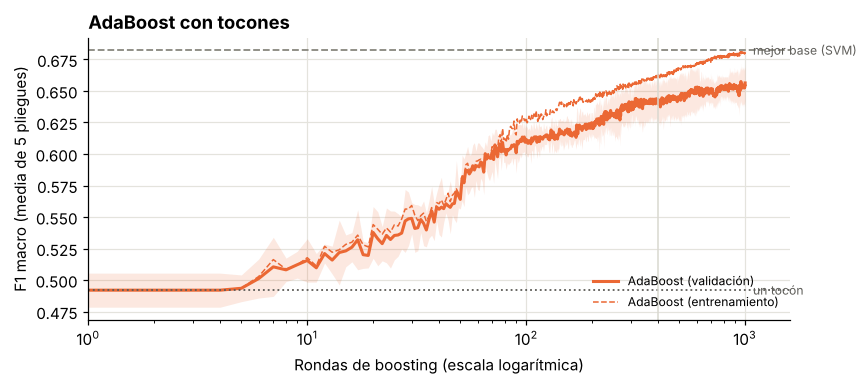

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
mv, sv = np.nanmean(f1_ada_val, 0), np.nanstd(f1_ada_val, 0, ddof=1)
ax.fill_between(rondas, mv - sv, mv + sv, color=COLOR_FAMILIA["boosting"], alpha=0.15, linewidth=0)
ax.plot(rondas, mv, color=COLOR_FAMILIA["boosting"], linewidth=2, label="AdaBoost (validación)")
ax.plot(rondas, np.nanmean(f1_ada_ent, 0), "--", color=COLOR_FAMILIA["boosting"], linewidth=1, label="AdaBoost (entrenamiento)")
ax.axhline(RESULTADOS["Tocón (profundidad 1)"]["f1"].mean(), color="#5f5e5a", linewidth=1.2, linestyle=":")
ax.text(N_RONDAS * 1.01, RESULTADOS["Tocón (profundidad 1)"]["f1"].mean(), "  un tocón", va="center", fontsize=8, color="#5f5e5a")
ax.axhline(RESULTADOS["SVM"]["f1"].mean(), color=COLOR_FAMILIA["base"], linewidth=1.2, linestyle="--")
ax.text(N_RONDAS * 1.01, RESULTADOS["SVM"]["f1"].mean(), "  mejor base (SVM)", va="center", fontsize=8, color="#5f5e5a")
ax.axvline(400, color="#d9d8d0", linewidth=1)
ax.set_xscale("log")
ax.set_xlim(1, N_RONDAS * 1.6)
ax.set_xlabel("Rondas de boosting (escala logarítmica)")
ax.set_ylabel("F1 macro (media de 5 pliegues)")
ax.legend(loc="lower right", fontsize=8, frameon=False)
ax.set_title("AdaBoost con tocones")
plt.tight_layout()
plt.show()

**¿Qué reduce *boosting*, y por qué?**

- **El tocón tiene sesgo alto.** Con un solo corte solo puede asignar dos clases: obtiene F1 = 0.492 tanto en entrenamiento como en validación, y su sensibilidad para *inscrito* es 0: nunca la predice. Que los dos F1 coincidan indica que el problema no es la varianza: el modelo es demasiado simple.
- ***Boosting* reduce el sesgo.** Cada ronda agrega un tocón entrenado sobre los estudiantes que el ensamble actual clasifica mal, así que el modelo combinado puede representar fronteras cada vez más complejas (una suma de muchos cortes, cada uno sobre un atributo). La prueba es la curva de **entrenamiento**: sube de 0.492 a 0.662 con 400 rondas y a 0.681 con 1000. *Bagging* no podía mover esa curva. La de validación la sigue de cerca (0.642 con 400 rondas y 0.656 con 1000), con una brecha de solo 0.02–0.025, así que la varianza sigue siendo baja.
- **El ritmo es lento.** Las primeras rondas casi no cambian nada (con 5 tocones, el F1 sigue en 0.49), porque hacen falta varios cortes para que aparezca la clase *inscrito*. La curva sigue subiendo a las 1000 rondas. Con tocones y tasa de aprendizaje 1, AdaBoost no alcanza al SVM (0.682), y su sensibilidad para *inscrito* (0.309 con 1000 rondas) sigue baja: como *bagging*, se entrena sin pesos por clase. El *gradient boosting* de la sección 8, con árboles más profundos y pesos por clase, es la versión eficaz de la misma idea.

## 6. Combinar los cinco base: votación dura, votación suave y *stacking*

- **Votación dura:** cada clasificador vota por una clase y gana la mayoría (con empate, gana la primera clase en orden alfabético).
- **Votación suave:** se promedian las probabilidades de los cinco y gana la clase con mayor promedio.
- ***Stacking*:** un meta-modelo logístico aprende a combinar las probabilidades de los cinco. Para que el meta-modelo no aprenda de predicciones hechas sobre datos que los base ya vieron, `StackingClassifier` genera sus entradas con una validación cruzada interna de 5 pliegues dentro de cada partición de entrenamiento. El meta-modelo usa `class_weight="balanced"`, por la misma razón que los base: el F1 macro castiga descuidar a `enrolled`.

**Probabilidades del SVM.** El SVM no produce probabilidades. Se envuelve en `CalibratedClassifierCV` (calibración sigmoide de Platt, validación cruzada interna de 5 pliegues); como el calibrador forma parte del modelo, `cross_validate` lo vuelve a ajustar en cada partición de entrenamiento y la calibración nunca ve el pliegue de validación. La votación dura usa el SVM original. Los otros cuatro ya tienen `predict_proba`.

In [11]:
CORTO = {"Árbol de decisión": "arbol", "Naive Bayes": "nb", "kNN": "knn", "SVM": "svm", "Regresión logística": "rl"}

def svm_calibrado():
    return CalibratedClassifierCV(clone(BASE["SVM"]), method="sigmoid", cv=CV_INTERNA)

def miembros(probabilidades):
    return [(CORTO[n], svm_calibrado() if (n == "SVM" and probabilidades) else clone(m)) for n, m in BASE.items()]

evaluar("Votación dura (5 base)", VotingClassifier(miembros(False), voting="hard"), "combinación")
evaluar("Votación suave (5 base)", VotingClassifier(miembros(True), voting="soft"), "combinación")
evaluar("Stacking (5 base, meta logístico)", StackingClassifier(
    miembros(True), final_estimator=LogisticRegression(max_iter=5000, class_weight="balanced"),
    cv=CV_INTERNA, stack_method="predict_proba"), "combinación")

base_mejor = RESULTADOS["SVM"]["f1"]
pd.DataFrame({n: {"F1 macro": RESULTADOS[n]["f1"].mean(), "desv. est.": RESULTADOS[n]["f1"].std(ddof=1),
                  "sens. enrolled": RESULTADOS[n]["sens"].mean(),
                  "ganancia sobre el SVM": RESULTADOS[n]["f1"].mean() - base_mejor.mean(),
                  "pliegues en que supera al SVM": int((RESULTADOS[n]["f1"] > base_mejor).sum())}
              for n in ["SVM", "Votación dura (5 base)", "Votación suave (5 base)", "Stacking (5 base, meta logístico)"]}).T.round(4)

Votación dura (5 base): F1 macro = 0.6878 ± 0.0094 · sens. enrolled = 0.539 · entrenamiento 1.09 s por pliegue
Votación suave (5 base): F1 macro = 0.6719 ± 0.0148 · sens. enrolled = 0.411 · entrenamiento 2.05 s por pliegue
Stacking (5 base, meta logístico): F1 macro = 0.6828 ± 0.0114 · sens. enrolled = 0.595 · entrenamiento 9.46 s por pliegue


,F1 macro,desv. est.,sens. enrolled,ganancia sobre el SVM,pliegues en que supera al SVM
SVM,0.6823,0.0103,0.6031,0.0000,0.0
Votación dura (5 base),0.6878,0.0094,0.5386,0.0054,3.0
Votación suave (5 base),0.6719,0.0148,0.4110,-0.0104,2.0
"Stacking (5 base, meta logístico)",0.6828,0.0114,0.5953,0.0005,2.0


### ¿Qué tan correlacionados están los errores?

Un ensamble que combina votos solo corrige un error si los demás miembros no se equivocan en el mismo estudiante. Se obtienen las predicciones fuera de pliegue de los cinco base (cada estudiante predicho por modelos que no lo vieron) y, para cada par, se calcula la **correlación de sus errores** (coeficiente φ entre los indicadores "se equivocó") y la proporción de estudiantes en que **ambos fallan**.

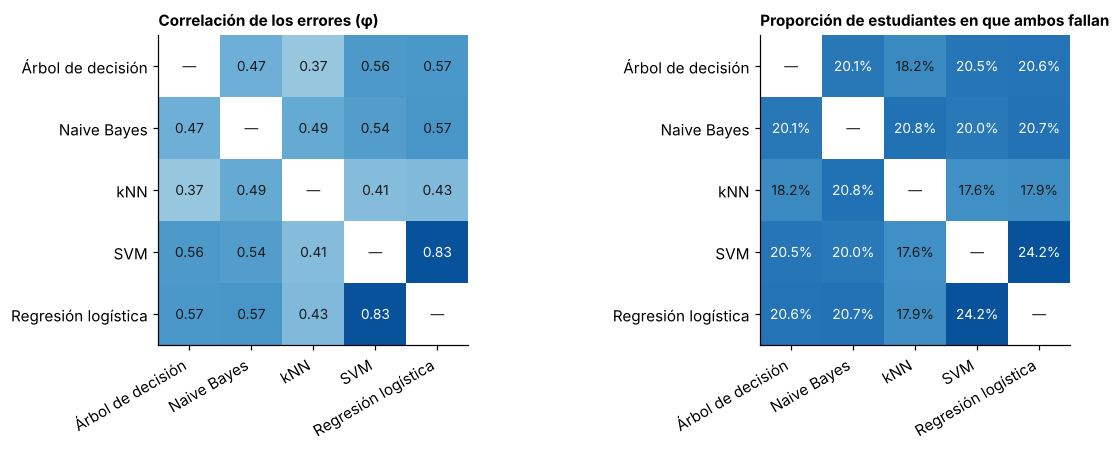

,Árbol de decisión,Naive Bayes,kNN,SVM,Regresión logística
tasa de error,0.316,0.315,0.322,0.277,0.277


,estudiantes,proporción
clasificadores que fallan,,
0,1652,0.467
1,557,0.157
2,338,0.096
3,271,0.077
4,315,0.089
5,406,0.115


In [12]:
pred_oof = pd.DataFrame({n: cross_val_predict(m, X, y, cv=PLIEGUES, n_jobs=N_JOBS) for n, m in BASE.items()},
                        index=y.index)
errores = pred_oof.ne(y, axis=0).astype(int)
phi = errores.corr()
doble_falla = pd.DataFrame({a: {b: ((errores[a] == 1) & (errores[b] == 1)).mean() for b in BASE} for a in BASE})

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
etq = list(BASE)
for ax, M, titulo, fmt in [(axes[0], phi, "Correlación de los errores (φ)", "{:.2f}"),
                           (axes[1], doble_falla, "Proporción de estudiantes en que ambos fallan", "{:.1%}")]:
    A = M.to_numpy().copy()
    np.fill_diagonal(A, np.nan)
    ax.imshow(A, cmap="Blues", vmin=0, vmax=np.nanmax(A) * 1.15)
    for i in range(5):
        for j in range(5):
            txt = "—" if i == j else fmt.format(M.iloc[i, j])
            ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                    color="white" if (i != j and M.iloc[i, j] > np.nanmax(A) * 0.8) else "#1a1a19")
    ax.set_xticks(range(5), etq, rotation=30, ha="right")
    ax.set_yticks(range(5), etq)
    ax.grid(False)
    ax.set_title(titulo, fontsize=10)
plt.tight_layout()
plt.show()

n_fallan = errores.sum(axis=1)
resumen_err = pd.DataFrame({
    "tasa de error": errores.mean(),
}).T
display(resumen_err.round(3))
dist_fallas = n_fallan.value_counts().reindex(range(6), fill_value=0)
pd.DataFrame({"estudiantes": dist_fallas, "proporción": (dist_fallas / len(y)).round(3)},
             index=pd.Index(range(6), name="clasificadores que fallan"))

In [13]:
# Correlación de errores por clase real: ¿dónde coinciden más los cinco?
por_clase = {}
for c in CLASES:
    m_c = y == c
    e_c = errores[m_c]
    tri = e_c.corr().to_numpy()[np.triu_indices(5, 1)]
    por_clase[NOMBRES_CLASE[c]] = {"estudiantes": int(m_c.sum()),
                                  "error medio de un base": e_c.mean().mean(),
                                  "fallan los cinco": (e_c.sum(axis=1) == 5).mean(),
                                  "fallan 3 o más (la mayoría)": (e_c.sum(axis=1) >= 3).mean(),
                                  "aciertan los cinco": (e_c.sum(axis=1) == 0).mean(),
                                  "φ medio entre pares": np.nanmean(tri)}
tri_all = phi.to_numpy()[np.triu_indices(5, 1)]
print(f"Correlación media de los errores entre pares: φ = {tri_all.mean():.2f} (de {tri_all.min():.2f} a {tri_all.max():.2f})")
print(f"Al menos uno acierta (cota del 'oráculo'): {(n_fallan < 5).mean():.1%} de los estudiantes")
pd.DataFrame(por_clase).T.round(3)

Correlación media de los errores entre pares: φ = 0.52 (de 0.37 a 0.83)
Al menos uno acierta (cota del 'oráculo'): 88.5% de los estudiantes


,estudiantes,error medio de un base,fallan los cinco,fallan 3 o más (la mayoría),aciertan los cinco,φ medio entre pares
Desertor,1137.0,0.337,0.171,0.318,0.463,0.613
Inscrito,635.0,0.523,0.216,0.477,0.104,0.380
Graduado,1767.0,0.199,0.042,0.185,0.600,0.476


**¿Qué implica?**

- **Los errores están muy correlacionados.** La correlación media entre pares es φ = 0.52. El par más parecido es **SVM–regresión logística (φ = 0.83)**: los dos son modelos de frontera casi lineal, con el mismo preprocesamiento y pesos balanceados, y en el 24 % de los estudiantes fallan los dos. kNN es el más distinto (φ de 0.37 a 0.49), pero también el más débil.
- **Lo que se equivocan juntos no se puede corregir votando.** El 11.5 % de los estudiantes es mal clasificado por **los cinco**, y en el 28 % se equivoca la mayoría (3 o más), así que la votación dura también falla. En *inscrito* es peor: un base típico falla en el 52 % de esos estudiantes, la mayoría falla en el 48 %, y solo en el 10 % aciertan los cinco. Es la confusión que la Práctica 3 ya identificó como en gran parte irreducible con la información del primer semestre.
- **Implicación.** Combinar ayuda solo cuando los miembros son buenos **y** se equivocan en estudiantes distintos. Aquí los dos mejores (SVM y regresión logística) son casi el mismo modelo, y los que aportan diversidad (kNN, Naive Bayes) son 5 a 10 puntos peores. Por eso las ganancias son mínimas: la votación dura gana +0.005 (en 3 de 5 pliegues, dentro de la variación entre pliegues) y el *stacking*, +0.0005. La votación suave **pierde** 0.010. Promedia probabilidades mal calibradas: las de Naive Bayes son casi siempre 0 o 1, y kNN y Naive Bayes no usan pesos por clase, así que el promedio diluye la corrección por desbalance de los otros tres y la sensibilidad para *inscrito* cae a 0.41. En la votación dura, en cambio, tres de los cinco votantes (árbol, SVM y regresión logística) usan pesos balanceados. El *stacking* aprende a corregir eso (su meta-modelo balanceado recupera 0.595 de sensibilidad para *inscrito*), pero no puede inventar la diversidad que falta. Solo el 88.5 % de los estudiantes tiene al menos un base que acierta: es el techo de cualquier votación entre estos cinco.

## 7. *Bagging* optimizado: Random Forest y Extra-Trees

Random Forest agrega a *bagging* una segunda fuente de diversidad: en cada nodo solo considera un subconjunto aleatorio de `max_features` atributos, lo que **decorrelaciona** los árboles. Extra-Trees va más lejos: elige también el umbral de corte al azar y, por omisión, entrena cada árbol con todos los datos (sin *bootstrap*).

Se usa `RandomizedSearchCV` con los mismos pliegues, 60 configuraciones por modelo y el F1 macro como criterio. El número de árboles se fija en 300: la curva de *bagging* de la sección 4 ya está en su meseta a partir de unos 100–200, y más árboles no cambian el sesgo ni la varianza de cada árbol, solo terminan de promediar. El preprocesamiento es el del árbol de la Práctica 3.

| Hiperparámetro | Valores | RF | ET |
|---|---|---|---|
| `max_features` (atributos por nodo) | `sqrt`, `log2`, 10 %, 20 %, 30 %, 50 %, 70 %, todos | ✓ | ✓ |
| `min_samples_leaf` | 1 a 40 | ✓ | ✓ |
| `max_depth` | 4 a 30, o sin límite (`None`) | ✓ | ✓ |
| `criterion` | gini, entropy, log_loss | ✓ | ✓ |
| `class_weight` | ninguno, balanced, balanced_subsample | ✓ | ✓ |
| `max_samples` (tamaño de la muestra *bootstrap*) | 50 %, 70 %, 100 % | ✓ | |
| `bootstrap` | sí, no | | ✓ |

In [14]:
BUSQUEDAS = {}
N_CONFIG = 60
N_ARBOLES_RF = 300

def legible(v):
    if isinstance(v, (float, np.floating)):
        return f"{v:.3g}"
    return "None" if v is None else v

def buscar(nombre, modelo, espacio, familia, n_iter=N_CONFIG):
    busq = RandomizedSearchCV(modelo, espacio, n_iter=n_iter, scoring=METRICAS, refit="f1_macro",
                              cv=PLIEGUES, random_state=SEMILLA, n_jobs=N_JOBS, error_score="raise")
    t0 = time.perf_counter()
    busq.fit(X, y)
    t = time.perf_counter() - t0
    cvr, i = busq.cv_results_, busq.best_index_
    f1 = [cvr[f"split{k}_test_f1_macro"][i] for k in range(len(PLIEGUES))]
    sens = [cvr[f"split{k}_test_sens_enrolled"][i] for k in range(len(PLIEGUES))]
    config = ", ".join(f"{re.sub(r'^clf__(estimator__)?', '', k)} = {legible(v)}" for k, v in sorted(busq.best_params_.items()))
    BUSQUEDAS[nombre] = busq
    registrar(nombre, familia, f1, sens, cvr["mean_fit_time"][i],
              clone(modelo).set_params(**busq.best_params_), config, t, n_iter)
    print(f"   {n_iter} configuraciones en {t:.0f} s; la mejor es la n.º {i + 1}: {config}")
    return busq

def grafica_meseta(nombre, param, etiqueta, log=False, color_por=None, colores=None):
    busq = BUSQUEDAS[nombre]
    cvr = pd.DataFrame(busq.cv_results_)
    f1 = cvr["mean_test_f1_macro"].to_numpy()
    n = np.arange(1, len(f1) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 3.6))
    a1.scatter(n, f1, s=14, color="#b4b2a7", label="configuración evaluada", zorder=2)
    a1.step(n, np.maximum.accumulate(f1), where="post", color="#2a78d6", linewidth=2,
            label="mejor F1 macro alcanzado", zorder=3)
    a1.axhline(RESULTADOS["SVM"]["f1"].mean(), color=COLOR_FAMILIA["base"], linestyle="--", linewidth=1)
    a1.text(len(f1), RESULTADOS["SVM"]["f1"].mean(), "mejor base (SVM) ", ha="right", va="bottom", fontsize=8, color="#5f5e5a")
    a1.set_ylim(max(np.quantile(f1, 0.1) - 0.02, f1.min() - 0.005), f1.max() + 0.012)
    a1.set_xlabel("Configuraciones evaluadas")
    a1.set_ylabel("F1 macro de validación")
    a1.legend(loc="lower right", fontsize=8, frameon=False)
    a1.set_title(f"{nombre}: meseta de la búsqueda")
    x = pd.to_numeric(cvr[f"param_{param}"], errors="coerce").to_numpy(dtype=float)
    grupos = cvr[f"param_{color_por}"].map(lambda v: "None (sin pesos)" if v is None or (isinstance(v, float) and np.isnan(v))
                                            else str(legible(v))) if color_por else pd.Series(["todas"] * len(f1))
    paleta = colores or {}
    tonos = ["#2a78d6", "#eb6834", "#1baf7a", "#8a8980", "#7b4fd0"]
    for g_i, g in enumerate(sorted(grupos.unique())):
        msk = (grupos == g).to_numpy()
        a2.scatter(x[msk], f1[msk], s=18, alpha=0.85, color=paleta.get(g, tonos[g_i % len(tonos)]), label=g)
    if log:
        a2.set_xscale("log")
    a2.set_ylim(a1.get_ylim())
    a2.set_xlabel(etiqueta)
    a2.set_ylabel("F1 macro de validación")
    if color_por:
        a2.legend(title=color_por.replace("clf__", "").replace("estimator__", ""), fontsize=8, title_fontsize=8, frameon=False)
    a2.set_title(f"F1 macro contra {etiqueta}", fontsize=10)
    plt.tight_layout()
    plt.show()

def mejores(nombre, n=5):
    cvr = pd.DataFrame(BUSQUEDAS[nombre].cv_results_)
    cols = [c for c in cvr.columns if c.startswith("param_")]
    t = cvr[cols + ["mean_test_f1_macro", "std_test_f1_macro", "mean_test_sens_enrolled"]].copy()
    t.columns = [re.sub(r"^param_clf__(estimator__)?", "", c) for c in t.columns]
    t = t.rename(columns={"mean_test_f1_macro": "F1 macro", "std_test_f1_macro": "desv. est.",
                          "mean_test_sens_enrolled": "sens. enrolled"})
    t.index = t.index + 1
    t.index.name = "config"
    t = t.sort_values("F1 macro", ascending=False).head(n)
    return t.astype(object).map(legible)

espacio_comun_bosque = {
    "clf__max_features": ["sqrt", "log2", 0.1, 0.2, 0.3, 0.5, 0.7, None],
    "clf__min_samples_leaf": randint(1, 41),
    "clf__max_depth": [None] + list(range(4, 31)),
    "clf__criterion": ["gini", "entropy", "log_loss"],
    "clf__class_weight": [None, "balanced", "balanced_subsample"],
}
rf = Pipeline([("prep", prep_arbol()), ("clf", RandomForestClassifier(
    n_estimators=N_ARBOLES_RF, random_state=SEMILLA, n_jobs=1))])
buscar("Random Forest", rf, {**espacio_comun_bosque, "clf__max_samples": [0.5, 0.7, None]}, "bagging")
mejores("Random Forest")

Random Forest: F1 macro = 0.6843 ± 0.0129 · sens. enrolled = 0.550 · entrenamiento 1.16 s por pliegue
   60 configuraciones en 221 s; la mejor es la n.º 47: class_weight = balanced, criterion = gini, max_depth = 22, max_features = 0.2, max_samples = 0.5, min_samples_leaf = 2


,class_weight,criterion,max_depth,max_features,max_samples,min_samples_leaf,F1 macro,desv. est.,sens. enrolled
config,,,,,,,,,
47,balanced,gini,22,0.2,0.5,2,0.684,0.0115,0.55
11,balanced,entropy,8,0.5,0.7,4,0.682,0.0142,0.609
2,balanced_subsample,entropy,21,0.7,None,11,0.68,0.0107,0.551
31,balanced,gini,22,0.3,0.5,3,0.68,0.0117,0.559
28,balanced,entropy,15,0.5,0.5,6,0.68,0.0103,0.586


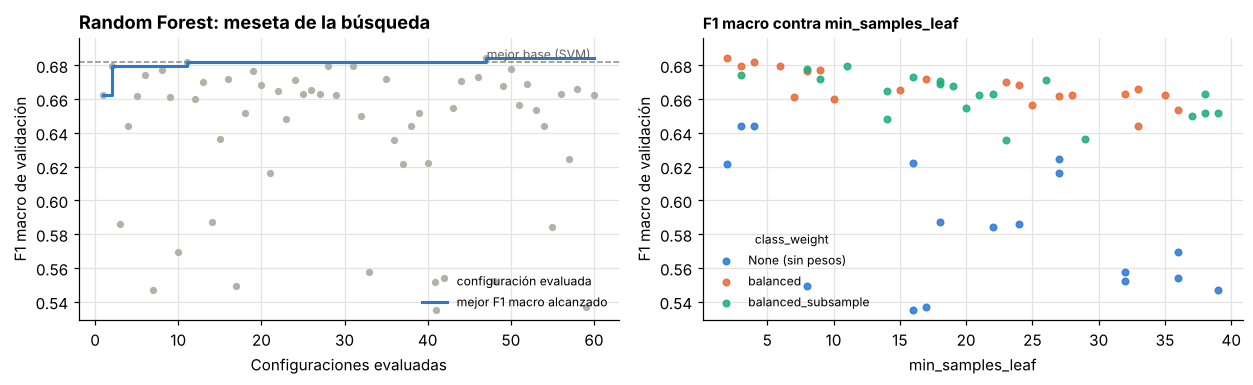

In [15]:
grafica_meseta("Random Forest", "clf__min_samples_leaf", "min_samples_leaf", color_por="clf__class_weight")

In [16]:
et = Pipeline([("prep", prep_arbol()), ("clf", ExtraTreesClassifier(
    n_estimators=N_ARBOLES_RF, random_state=SEMILLA, n_jobs=1))])
buscar("Extra-Trees", et, {**espacio_comun_bosque, "clf__bootstrap": [False, True]}, "bagging")
mejores("Extra-Trees")

Extra-Trees: F1 macro = 0.6755 ± 0.0088 · sens. enrolled = 0.565 · entrenamiento 2.28 s por pliegue
   60 configuraciones en 251 s; la mejor es la n.º 14: bootstrap = True, class_weight = balanced, criterion = entropy, max_depth = 18, max_features = 0.7, min_samples_leaf = 8


,bootstrap,class_weight,criterion,max_depth,max_features,min_samples_leaf,F1 macro,desv. est.,sens. enrolled
config,,,,,,,,,
14,True,balanced,entropy,18,0.7,8,0.676,0.0079,0.565
30,True,balanced,entropy,15,0.5,6,0.674,0.00451,0.559
7,False,balanced,entropy,17,0.5,3,0.674,0.0132,0.46
41,True,balanced_subsample,gini,8,None,5,0.673,0.0083,0.578
48,True,balanced,gini,22,0.2,2,0.669,0.0073,0.485


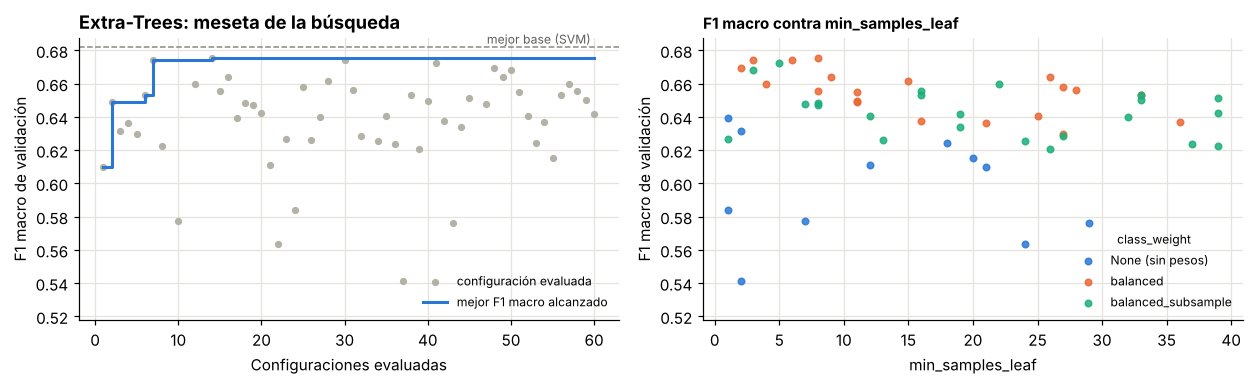

In [17]:
grafica_meseta("Extra-Trees", "clf__min_samples_leaf", "min_samples_leaf", color_por="clf__class_weight")

**Resultado del *bagging* optimizado.**

- **Random Forest** llega a 0.684 ± 0.013: +0.021 sobre el *bagging* simple y +0.002 sobre el SVM, es decir, apenas lo empata. La mejor configuración usa `max_features = 0.2` (cada nodo elige entre el 20 % de las columnas) y `max_samples = 0.5` (cada árbol ve la mitad de los estudiantes). Las dos opciones **decorrelacionan** los árboles, el término ρσ² que *bagging* no podía reducir, a cambio de árboles individuales algo peores. La otra mitad de la mejora viene de `class_weight = balanced`: la sensibilidad de *inscrito* sube de 0.335 (*bagging*) a 0.550.
- **Extra-Trees** queda en 0.676 ± 0.009, por debajo de Random Forest. Su mejor configuración usa `bootstrap = True` y `max_features = 0.7`, es decir, reintroduce el muestreo que lo distingue de Random Forest y compensa con más atributos por nodo la aleatoriedad de los umbrales. Con 30 atributos, la mayoría binarios o con pocos valores, elegir el umbral al azar no aporta mucha diversidad adicional y sí hace cada árbol más débil.
- **La meseta llega pronto.** En las dos búsquedas, el mejor valor aparece en las primeras 15 configuraciones a menos de 0.003 del máximo final, y las cinco mejores configuraciones están en un rango de 0.004–0.007, menor que la desviación entre pliegues. Lo que separa las configuraciones buenas de las malas es casi solo **`class_weight`**: en la gráfica de la derecha, las configuraciones sin pesos (`None`) quedan entre 0.53 y 0.65, y todas las cercanas a la meseta usan pesos balanceados. Las hojas pequeñas (`min_samples_leaf` ≤ 10) son ligeramente mejores.

## 8. *Boosting* optimizado: XGBoost y LightGBM

Los dos implementan *gradient boosting*: cada árbol nuevo se ajusta al gradiente de la pérdida logarítmica multinomial del ensamble actual, con una tasa de aprendizaje que reduce su aporte. Se diferencian en cómo crecen los árboles: XGBoost los crece **por niveles**, hasta `max_depth`; LightGBM los crece **por hojas**, abriendo siempre la hoja que más reduce la pérdida, hasta `num_leaves`.

**Pesos por clase.** LightGBM acepta `class_weight` directamente. XGBoost no: los pesos se pasan como `sample_weight` al entrenar. Para que se calculen dentro de cada partición de entrenamiento, se usa un pequeño envoltorio (`ClasificadorPonderado`) que, en `fit`, calcula los pesos *balanced* de esa partición y los eleva a una `potencia` (0 = sin pesos, 0.5 = intermedios, 1 = balanceados). El envoltorio también convierte las etiquetas de texto a 0, 1, 2, como pide XGBoost.

60 configuraciones por biblioteca, mismos pliegues, F1 macro como criterio:

| Hiperparámetro | XGBoost | LightGBM |
|---|---|---|
| número de árboles | 100 a 800 | 100 a 800 |
| tasa de aprendizaje | log-uniforme [0.005, 0.2] | log-uniforme [0.005, 0.2] |
| tamaño del árbol | `max_depth` 2 a 8 | `num_leaves` 4 a 63; `max_depth` 3–10 o sin límite |
| tamaño mínimo de hoja | `min_child_weight` log-uniforme [0.5, 20] | `min_child_samples` 5 a 80 |
| regularización de las hojas | `reg_lambda` (L2) log-uniforme [10⁻², 30], `reg_alpha` (L1) log-uniforme [10⁻³, 10] | `reg_lambda` log-uniforme [10⁻³, 30], `reg_alpha` log-uniforme [10⁻³, 10] |
| submuestreo de filas | `subsample` uniforme [0.5, 1] | `subsample` uniforme [0.5, 1] (en cada iteración) |
| submuestreo de columnas | `colsample_bytree` uniforme [0.2, 1] | `colsample_bytree` uniforme [0.2, 1] |
| pesos por clase | potencia 0, 0.5 o 1 | ninguno o balanced |

In [18]:
class ClasificadorPonderado(ClassifierMixin, BaseEstimator):
    # Entrena `estimator` con pesos por clase calculados en su propia partición: balanced ** potencia.
    def __init__(self, estimator=None, potencia=1.0):
        self.estimator = estimator
        self.potencia = potencia

    def fit(self, X, y):
        self.codificador_ = LabelEncoder().fit(y)
        self.classes_ = self.codificador_.classes_
        y_num = self.codificador_.transform(y)
        pesos = compute_sample_weight("balanced", y_num) ** self.potencia
        self.estimator_ = clone(self.estimator).fit(X, y_num, sample_weight=pesos)
        return self

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

xgb = Pipeline([("prep", prep_arbol()), ("clf", ClasificadorPonderado(XGBClassifier(
    tree_method="hist", eval_metric="mlogloss", random_state=SEMILLA, n_jobs=1)))])
espacio_xgb = {
    "clf__estimator__n_estimators": randint(100, 801),
    "clf__estimator__learning_rate": loguniform(0.005, 0.2),
    "clf__estimator__max_depth": randint(2, 9),
    "clf__estimator__min_child_weight": loguniform(0.5, 20),
    "clf__estimator__reg_lambda": loguniform(1e-2, 30),
    "clf__estimator__reg_alpha": loguniform(1e-3, 10),
    "clf__estimator__subsample": uniform(0.5, 0.5),
    "clf__estimator__colsample_bytree": uniform(0.2, 0.8),
    "clf__potencia": [0.0, 0.5, 1.0],
}
buscar("XGBoost", xgb, espacio_xgb, "boosting")
mejores("XGBoost")

XGBoost: F1 macro = 0.6909 ± 0.0162 · sens. enrolled = 0.502 · entrenamiento 1.19 s por pliegue
   60 configuraciones en 169 s; la mejor es la n.º 18: colsample_bytree = 0.375, learning_rate = 0.0392, max_depth = 5, min_child_weight = 1.91, n_estimators = 596, reg_alpha = 0.0104, reg_lambda = 0.0722, subsample = 0.848, potencia = 1


,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample,potencia,F1 macro,desv. est.,sens. enrolled
config,,,,,,,,,,,,
18,0.375,0.0392,5,1.91,596,0.0104,0.0722,0.848,1,0.691,0.0145,0.502
24,0.902,0.0129,5,0.953,723,0.166,0.694,0.621,0.5,0.69,0.0161,0.449
14,0.684,0.0366,6,1.16,259,0.249,2.61,0.94,0.5,0.689,0.0157,0.444
13,0.289,0.0253,4,0.561,340,0.0181,0.587,0.954,1,0.688,0.0139,0.608
11,0.276,0.0196,7,1.66,198,0.232,0.0902,0.781,1,0.687,0.0119,0.554


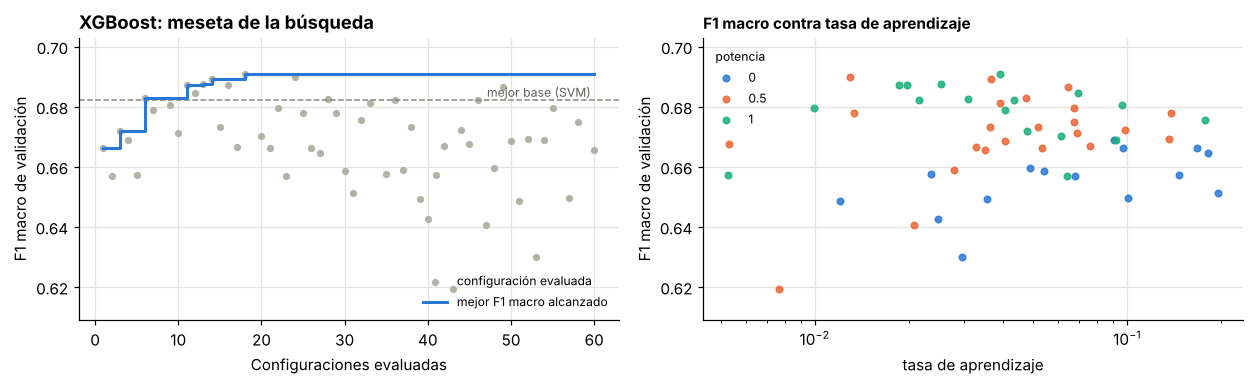

In [19]:
grafica_meseta("XGBoost", "clf__estimator__learning_rate", "tasa de aprendizaje", log=True, color_por="clf__potencia")

In [20]:
lgbm = Pipeline([("prep", prep_arbol()), ("clf", LGBMClassifier(
    subsample_freq=1, random_state=SEMILLA, n_jobs=1, verbose=-1))])
espacio_lgbm = {
    "clf__n_estimators": randint(100, 801),
    "clf__learning_rate": loguniform(0.005, 0.2),
    "clf__num_leaves": randint(4, 64),
    "clf__max_depth": [-1, 3, 4, 5, 6, 8, 10],
    "clf__min_child_samples": randint(5, 81),
    "clf__reg_lambda": loguniform(1e-3, 30),
    "clf__reg_alpha": loguniform(1e-3, 10),
    "clf__subsample": uniform(0.5, 0.5),
    "clf__colsample_bytree": uniform(0.2, 0.8),
    "clf__class_weight": [None, "balanced"],
}
buscar("LightGBM", lgbm, espacio_lgbm, "boosting")
mejores("LightGBM")

LightGBM: F1 macro = 0.6841 ± 0.0102 · sens. enrolled = 0.586 · entrenamiento 0.43 s por pliegue
   60 configuraciones en 126 s; la mejor es la n.º 60: class_weight = balanced, colsample_bytree = 0.516, learning_rate = 0.00741, max_depth = 6, min_child_samples = 12, n_estimators = 221, num_leaves = 31, reg_alpha = 0.387, reg_lambda = 0.0547, subsample = 0.615


,class_weight,colsample_bytree,learning_rate,max_depth,min_child_samples,n_estimators,num_leaves,reg_alpha,reg_lambda,subsample,F1 macro,desv. est.,sens. enrolled
config,,,,,,,,,,,,,
60,balanced,0.516,0.00741,6,12,221,31,0.387,0.0547,0.615,0.684,0.00913,0.586
22,balanced,0.61,0.0115,10,56,588,36,0.0389,0.208,0.919,0.682,0.018,0.532
44,balanced,0.659,0.00803,6,55,526,40,0.319,4.71,0.826,0.682,0.00773,0.595
30,balanced,0.576,0.014,8,41,379,32,0.0516,21.3,0.982,0.682,0.00449,0.587
38,balanced,0.417,0.0252,10,66,226,12,0.568,0.00182,0.958,0.682,0.00695,0.589


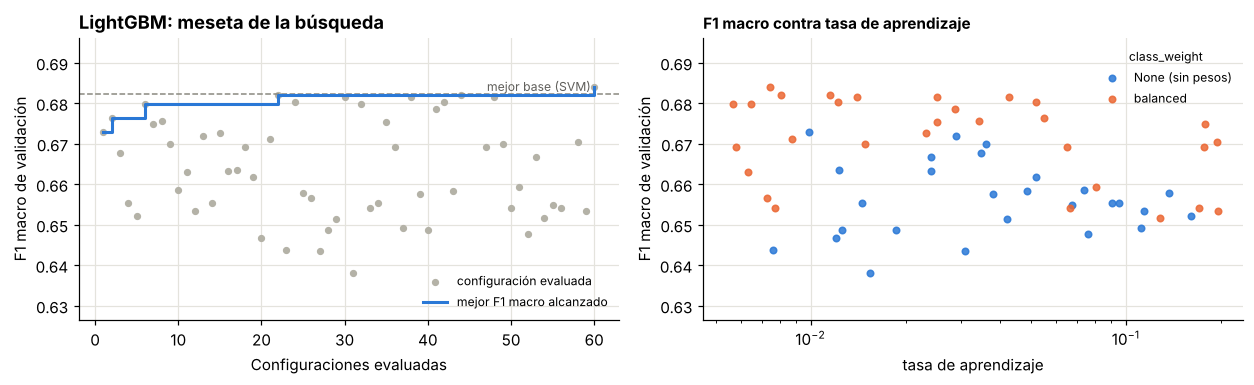

In [21]:
grafica_meseta("LightGBM", "clf__learning_rate", "tasa de aprendizaje", log=True, color_por="clf__class_weight")

**Resultado del *boosting* optimizado.**

- **XGBoost** obtiene el mejor F1 macro de toda la práctica: **0.691 ± 0.016**, +0.009 sobre el SVM. Su mejor configuración es un *boosting* moderado: 596 árboles de profundidad 5, tasa de aprendizaje 0.039, solo el 37.5 % de las columnas por árbol, el 85 % de las filas y pesos balanceados (`potencia = 1`). Llegó a la meseta en la configuración 18. En la gráfica de la derecha, las configuraciones sin pesos (`potencia = 0`) quedan todas por debajo de 0.67; las de pesos intermedios o completos ocupan la parte alta.
- **LightGBM** llega a 0.684 ± 0.009, empatado con Random Forest. Su mejor configuración es muy conservadora: tasa de aprendizaje 0.0074 con solo 221 árboles, de profundidad máxima 6. Es decir, un modelo fuertemente "encogido" que se detiene antes de ajustar los detalles del entrenamiento. Otra vez, todas las configuraciones sin pesos (`None`) quedan por debajo de 0.675.
- **Las dos ganancias son pequeñas frente a la variación entre pliegues** (± 0.009 a ± 0.016). XGBoost supera al SVM en promedio, pero la diferencia entre XGBoost y LightGBM (0.007) es del mismo tamaño que esa variación. A diferencia de AdaBoost con tocones, estos modelos usan árboles de varias hojas (pueden representar interacciones desde la primera ronda), tasa de aprendizaje pequeña con submuestreo (lo que reduce también la varianza) y regularización explícita de las hojas. Combinan la reducción de sesgo del *boosting* con mecanismos de control de varianza, y por eso son los únicos ensambles que superan con claridad a los árboles.

## 9. Tabla comparativa de la deserción

Todos los modelos, ordenados por F1 macro (media ± desviación estándar entre los cinco pliegues). La sensibilidad de `enrolled` es el promedio entre pliegues. El tiempo de entrenamiento es el de un ajuste completo con 4/5 de los datos, promediado entre pliegues; para los modelos optimizados se agrega el tiempo total de su búsqueda. Para *bagging* y AdaBoost, el tiempo es el de entrenar todos sus árboles.

*Advertencia (igual que en la Práctica 3):* en los modelos optimizados, los mismos pliegues sirven para elegir la configuración y para evaluarla, así que su F1 es ligeramente optimista. El de los cinco base también lo es, porque se eligieron así en la Práctica 3; los ensambles sin búsqueda (votaciones, *stacking*, *bagging*, AdaBoost) no tienen ese sesgo.

In [22]:
ETIQUETA_FAMILIA = {"base": "base (Práctica 3)", "individual": "árbol individual", "bagging": "bagging",
                    "boosting": "boosting", "combinación": "combinación de los base"}
filas = []
for nombre, r in RESULTADOS.items():
    filas.append({"modelo": nombre, "familia": ETIQUETA_FAMILIA[r["familia"]],
                  "F1 macro": f"{r['f1'].mean():.3f} ± {r['f1'].std(ddof=1):.3f}",
                  "_f1": r["f1"].mean(),
                  "ganancia sobre el SVM": r["f1"].mean() - RESULTADOS["SVM"]["f1"].mean(),
                  "sens. enrolled": r["sens"].mean(),
                  "entrenamiento (s/pliegue)": r["t_fit"],
                  "búsqueda (s)": r["t_busqueda"]})
tabla_desercion = (pd.DataFrame(filas).sort_values("_f1", ascending=False).drop(columns="_f1")
                   .reset_index(drop=True))
tabla_desercion.index = tabla_desercion.index + 1
MEJOR_DES = tabla_desercion.loc[1, "modelo"]
display(tabla_desercion.style.format({"ganancia sobre el SVM": "{:+.3f}", "sens. enrolled": "{:.3f}",
                                      "entrenamiento (s/pliegue)": "{:.2f}", "búsqueda (s)": "{:.0f}"},
                                     na_rep="—"))

,modelo,familia,F1 macro,ganancia sobre el SVM,sens. enrolled,entrenamiento (s/pliegue),búsqueda (s)
1,XGBoost,boosting,0.691 ± 0.016,+0.009,0.502,1.19,169
2,Votación dura (5 base),combinación de los base,0.688 ± 0.009,+0.005,0.539,1.09,—
3,Random Forest,bagging,0.684 ± 0.013,+0.002,0.550,1.16,221
4,LightGBM,boosting,0.684 ± 0.010,+0.002,0.586,0.43,126
5,"Stacking (5 base, meta logístico)",combinación de los base,0.683 ± 0.011,+0.000,0.595,9.46,—
6,SVM,base (Práctica 3),0.682 ± 0.010,+0.000,0.603,0.48,—
7,Regresión logística,base (Práctica 3),0.680 ± 0.010,-0.002,0.570,0.39,—
8,Extra-Trees,bagging,0.676 ± 0.009,-0.007,0.565,2.28,251
9,Votación suave (5 base),combinación de los base,0.672 ± 0.015,-0.010,0.411,2.05,—
10,Bagging (400 árboles sin límite),bagging,0.663 ± 0.023,-0.019,0.335,5.86,—


Mejor configuración encontrada para cada modelo optimizado:

In [23]:
pd.DataFrame({n: {"configuraciones": int(RESULTADOS[n]["n_config"]), "mejor configuración": RESULTADOS[n]["config"]}
              for n in BUSQUEDAS}).T

,configuraciones,mejor configuración
Random Forest,60,"class_weight = balanced, criterion = gini, max_depth = 22, max_features = 0.2, max_samples = 0.5, min_samples_leaf = 2"
Extra-Trees,60,"bootstrap = True, class_weight = balanced, criterion = entropy, max_depth = 18, max_features = 0.7, min_samples_leaf..."
XGBoost,60,"colsample_bytree = 0.375, learning_rate = 0.0392, max_depth = 5, min_child_weight = 1.91, n_estimators = 596, reg_al..."
LightGBM,60,"class_weight = balanced, colsample_bytree = 0.516, learning_rate = 0.00741, max_depth = 6, min_child_samples = 12, n..."


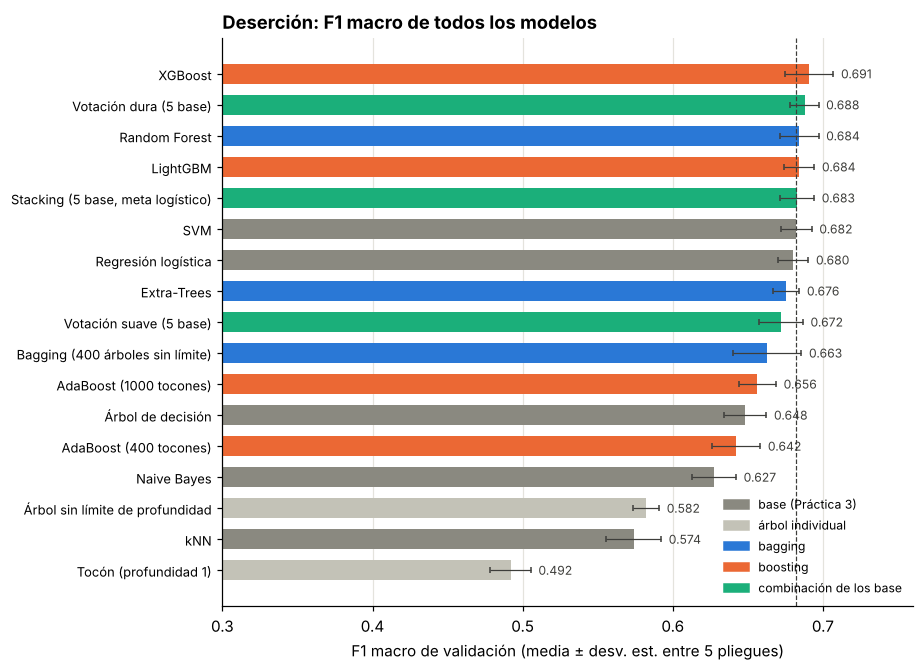

In [24]:
orden = tabla_desercion["modelo"].tolist()[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6.2))
medias = [RESULTADOS[n]["f1"].mean() for n in orden]
desv = [RESULTADOS[n]["f1"].std(ddof=1) for n in orden]
ax.barh(range(len(orden)), medias, xerr=desv, height=0.65,
        color=[COLOR_FAMILIA[RESULTADOS[n]["familia"]] for n in orden],
        error_kw=dict(ecolor="#3d3d3a", capsize=2, linewidth=0.8))
for i, (m_, s_) in enumerate(zip(medias, desv)):
    ax.text(m_ + s_ + 0.005, i, f"{m_:.3f}", va="center", fontsize=8, color="#3d3d3a")
ax.axvline(RESULTADOS["SVM"]["f1"].mean(), color="#3d3d3a", linestyle="--", linewidth=0.8)
ax.set_yticks(range(len(orden)), orden, fontsize=8.5)
ax.set_xlim(0.3, 0.76)
ax.set_xlabel("F1 macro de validación (media ± desv. est. entre 5 pliegues)")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLOR_FAMILIA[f], label=ETIQUETA_FAMILIA[f]) for f in
                   ["base", "individual", "bagging", "boosting", "combinación"]],
          loc="lower right", fontsize=8, frameon=False)
ax.set_title("Deserción: F1 macro de todos los modelos")
plt.tight_layout()
plt.show()

### Matriz de confusión del mejor modelo

Con las predicciones fuera de pliegue del mejor modelo (cada estudiante predicho por el modelo entrenado en los pliegues en los que no participó), junto a la del SVM de la Práctica 3 para comparar.

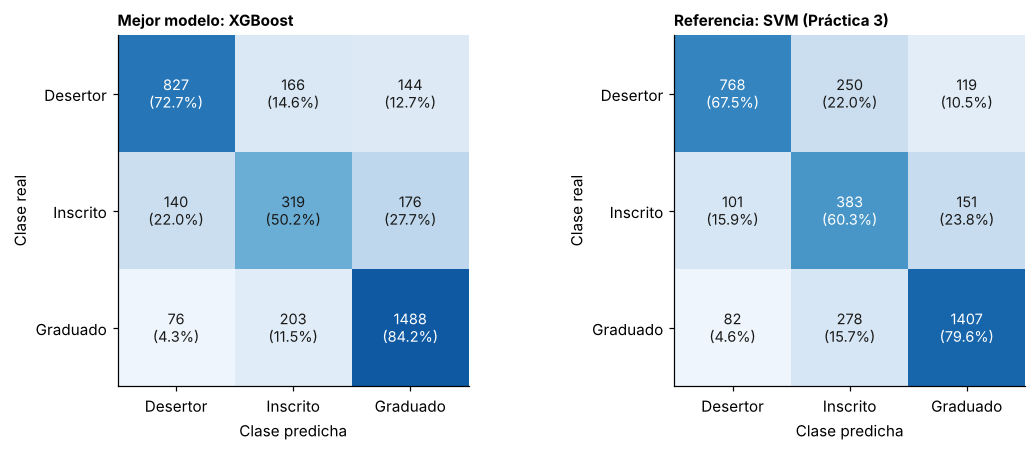

,pred.: Desertor,pred.: Inscrito,pred.: Graduado
diferencia (mejor − SVM),,,
real: Desertor,59,-84,25
real: Inscrito,39,-64,25
real: Graduado,-6,-75,81


In [25]:
def matriz(ax, y_real, y_pred, etiquetas, nombres, titulo):
    cm = confusion_matrix(y_real, y_pred, labels=etiquetas)
    cm_f = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_f, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(etiquetas)):
        for j in range(len(etiquetas)):
            ax.text(j, i, f"{cm[i, j]}\n({cm_f[i, j]:.1%})", ha="center", va="center", fontsize=9.5,
                    color="white" if cm_f[i, j] > 0.55 else "#1a1a19")
    ax.set_xticks(range(len(etiquetas)), nombres)
    ax.set_yticks(range(len(etiquetas)), nombres)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.grid(False)
    ax.set_title(titulo, fontsize=10)
    return cm

pred_mejor_des = cross_val_predict(RESULTADOS[MEJOR_DES]["modelo"], X, y, cv=PLIEGUES, n_jobs=N_JOBS)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
etq = [NOMBRES_CLASE[c] for c in CLASES]
cm_mejor = matriz(axes[0], y, pred_mejor_des, CLASES, etq, f"Mejor modelo: {MEJOR_DES}")
cm_svm = matriz(axes[1], y, pred_oof["SVM"], CLASES, etq, "Referencia: SVM (Práctica 3)")
plt.tight_layout()
plt.show()
pd.DataFrame(cm_mejor - cm_svm, index=[f"real: {e}" for e in etq], columns=[f"pred.: {e}" for e in etq]).rename_axis(
    "diferencia (mejor − SVM)")

**¿Cuánto ganan los ensambles sobre los cinco base bien ajustados? Poco.** El mejor modelo, XGBoost, obtiene 0.691 ± 0.016 frente a 0.682 ± 0.010 del SVM: **+0.009**, menos que la desviación entre pliegues. Detrás vienen, en un rango de 0.006, la votación dura (0.688), Random Forest y LightGBM (0.684), el *stacking* (0.683) y el propio SVM. Los ensambles sin ajuste (*bagging* simple y AdaBoost con tocones) quedan **por debajo** de los mejores base, aunque mejoran mucho a los árboles de los que parten (+0.08 y +0.16).

**La matriz de confusión muestra en qué consiste la ganancia.** XGBoost no clasifica mejor a los inscritos: predice *inscrito* 223 veces menos que el SVM. Con eso recupera 59 desertores y 81 graduados que el SVM mandaba a *inscrito*, pero pierde 64 inscritos que ahora van a parar a las otras dos clases. Su sensibilidad para *inscrito* baja de 0.603 a 0.502. Gana F1 macro porque sube la precisión de *inscrito* y el F1 de las otras dos clases, pero la clase difícil sigue igual de difícil. El techo lo pone la información disponible al cierre del primer semestre, no el clasificador.

**Costo.** El SVM se entrena en menos de medio segundo por pliegue. XGBoost tarda alrededor de 1 s por pliegue, más unos 3 minutos de búsqueda, y el *stacking*, unos 9 s por pliegue sin búsqueda (los tiempos exactos varían entre ejecuciones; la tabla muestra los de esta). Para este problema, un SVM o una regresión logística bien ajustados están prácticamente a la par de los ensambles, y son más baratos y más fáciles de interpretar.

# Parte 2 · Bank Marketing

## 10. Datos y protocolo

41 188 llamadas de una campaña de un banco portugués (mayo de 2008 a noviembre de 2010; Moro *et al.*, 2014). La variable objetivo `y` indica si el cliente contrató un depósito a plazo. Se quita `duration` (la duración de la llamada), que solo se conoce después de llamar y por lo tanto no sirve para decidir a quién llamar.

**Protocolo del enunciado.** El F1 macro de cada modelo sale de
`cross_validate(modelo, X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2026), scoring="f1_macro")`,
con `X` igual al archivo sin `duration` ni `y`, y con `y` en 1 (*yes*) y 0 (*no*). Todo lo que se ajusta con datos (codificación, imputación, escalado, pesos, umbral, meta-modelo) va dentro de `modelo`. Aquí se pide además la sensibilidad de la clase *yes* (`"recall"`), así que se pasa un diccionario de métricas: el F1 macro que devuelve es exactamente el mismo número.

In [26]:
banco = pd.read_csv(RUTA_BANCO, sep=";")
Xb = banco.drop(columns=["duration", "y"])
yb = (banco["y"] == "yes").astype(int)
CV_B = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_BANCO)
METRICAS_B = {"f1_macro": "f1_macro", "sens_yes": "recall"}

CAT_B = Xb.select_dtypes(include=["object", "string"]).columns.tolist()
NUM_B = [c for c in Xb.columns if c not in CAT_B]
print(f"X: {Xb.shape[0]} filas × {Xb.shape[1]} atributos ({len(CAT_B)} categóricos, {len(NUM_B)} numéricos)")
print(f"y = 1 (yes): {yb.sum()} ({yb.mean():.1%});  y = 0 (no): {(1 - yb).sum()}")
print(f"pdays = 999 (sin contacto previo): {(Xb['pdays'] == 999).mean():.1%} de las filas")
pd.DataFrame({"niveles": Xb[CAT_B].nunique(), "'unknown'": (Xb[CAT_B] == "unknown").sum(),
              "tasa de yes (min–max entre niveles)": [
                  f"{banco.groupby(c)['y'].apply(lambda s: (s == 'yes').mean()).min():.1%} – "
                  f"{banco.groupby(c)['y'].apply(lambda s: (s == 'yes').mean()).max():.1%}" for c in CAT_B]})

X: 41188 filas × 19 atributos (10 categóricos, 9 numéricos)
y = 1 (yes): 4640 (11.3%);  y = 0 (no): 36548
pdays = 999 (sin contacto previo): 96.3% de las filas


,niveles,'unknown',tasa de yes (min–max entre niveles)
job,12,330,6.9% – 31.4%
marital,4,80,10.2% – 15.0%
education,8,1731,7.8% – 22.2%
default,3,8597,0.0% – 12.9%
housing,3,990,10.8% – 11.6%
loan,3,990,10.8% – 11.3%
contact,2,0,5.2% – 14.7%
month,10,0,6.4% – 50.5%
day_of_week,5,0,9.9% – 12.1%
poutcome,3,0,8.8% – 65.1%


Lo que distingue a este problema de la deserción, y que guía las decisiones:

- **Desbalance fuerte y binario:** 11.3 % de *yes*. Con el umbral de 0.5, casi cualquier modelo predice *no* de más. El F1 macro promedia el F1 de *yes* y el de *no*; el de *no* es alto casi siempre (≈ 0.93), así que la competencia se decide en el F1 de *yes*, que depende del **umbral**.
- **Muchos datos y pocos atributos:** 41 188 filas y 19 atributos. Hay datos de sobra para modelos flexibles, y el SVM con kernel (cuyo costo crece con el cuadrado del número de filas) deja de ser práctico.
- **Atributos mixtos:** 10 categóricos con un nivel `unknown` (que se conserva como categoría: no es un faltante al azar) y 9 numéricos; `pdays = 999` es un código de "nunca contactado", no un número.
- **Contexto económico:** los cinco indicadores (`emp.var.rate`, `euribor3m`, `nr.employed`…) cambian con el mes de la campaña y son de los atributos más informativos (Moro *et al.*, 2014).

### Preprocesamiento (dentro de cada modelo)

- **Modelos lineales y de distancias** (regresión logística, kNN, Naive Bayes): categóricos en *one-hot*; `pdays = 999` se reemplaza por la mediana de los contactados y se agrega un indicador "sin contacto previo" (`SimpleImputer(missing_values=999, add_indicator=True)`); todos los numéricos se estandarizan.
- **Árboles y ensambles de árboles:** categóricos con un código entero (`OrdinalEncoder`) y numéricos sin cambio; un árbol separa `pdays = 999` con un solo corte.

### Balanceo de clases

Se comparan tres formas, todas dentro del modelo: **pesos por clase** (`class_weight="balanced"` o `scale_pos_weight`), **ajuste del umbral** de decisión con `TunedThresholdClassifierCV` (elige, con una validación cruzada interna de 5 pliegues sobre la partición de entrenamiento, el umbral que maximiza el F1 macro, y luego reentrena con toda la partición), y la combinación de ambas.

In [27]:
CV_UMBRAL = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_BANCO)

def prep_lineal_b():
    pdays = Pipeline([("imp", SimpleImputer(missing_values=999, strategy="median", add_indicator=True)),
                      ("esc", StandardScaler())])
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_B),
                              ("pdays", pdays, ["pdays"]),
                              ("num", StandardScaler(), [c for c in NUM_B if c != "pdays"])])

def prep_arbol_b():
    return ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_B),
                              ("num", "passthrough", NUM_B)])

def con_umbral(modelo):
    return TunedThresholdClassifierCV(modelo, scoring="f1_macro", cv=CV_UMBRAL)

RES_B = {}
def evaluar_b(nombre, modelo, familia, balanceo, n_jobs=N_JOBS, config="—", t_busqueda=np.nan):
    r = cross_validate(modelo, Xb, yb, cv=CV_B, scoring=METRICAS_B, n_jobs=n_jobs)
    RES_B[nombre] = {"familia": familia, "balanceo": balanceo, "f1": r["test_f1_macro"], "sens": r["test_sens_yes"],
                     "t_fit": r["fit_time"].mean(), "modelo": modelo, "config": config, "t_busqueda": t_busqueda}
    print(f"{nombre}: F1 macro = {r['test_f1_macro'].mean():.4f} ± {r['test_f1_macro'].std(ddof=1):.4f} · "
          f"sens. yes = {r['test_sens_yes'].mean():.3f} · entrenamiento {r['fit_time'].mean():.1f} s por pliegue")

## 11. Modelos probados

### 11.1 Referencia y clasificadores individuales

Un clasificador que siempre dice *no* da la referencia mínima. Después, los clasificadores de la Práctica 3 que escalan a 41 mil filas, con pesos balanceados y con ajuste de umbral. El SVM con kernel no se incluye: su entrenamiento crece aproximadamente con el cuadrado del número de filas y, con 33 mil filas por partición (y seis ajustes por pliegue al ajustar el umbral), tardaría horas sin ventaja esperable sobre la regresión logística, que en la deserción quedó empatada con él.

In [28]:
evaluar_b("Siempre 'no'", DummyClassifier(strategy="most_frequent"), "referencia", "—")

rl_b = Pipeline([("prep", prep_lineal_b()), ("clf", LogisticRegression(max_iter=3000))])
evaluar_b("Regresión logística", rl_b, "individual", "ninguno (umbral 0.5)")
evaluar_b("Regresión logística (balanced)", clone(rl_b).set_params(clf__class_weight="balanced"), "individual", "pesos")
evaluar_b("Regresión logística + umbral", con_umbral(rl_b), "individual", "umbral")

arbol_b = Pipeline([("prep", prep_arbol_b()), ("clf", DecisionTreeClassifier(
    max_depth=6, min_samples_leaf=50, random_state=SEMILLA_BANCO))])
evaluar_b("Árbol de decisión (balanced)", clone(arbol_b).set_params(clf__class_weight="balanced"), "individual", "pesos")
evaluar_b("Árbol de decisión + umbral", con_umbral(arbol_b), "individual", "umbral")

evaluar_b("Naive Bayes gaussiano + umbral", con_umbral(Pipeline([("prep", prep_lineal_b()), ("clf", GaussianNB())])),
          "individual", "umbral")
evaluar_b("kNN (k = 50) + umbral", con_umbral(Pipeline([("prep", prep_lineal_b()), ("clf", KNeighborsClassifier(
    n_neighbors=50, weights="distance"))])), "individual", "umbral")

Siempre 'no': F1 macro = 0.4702 ± 0.0000 · sens. yes = 0.000 · entrenamiento 0.0 s por pliegue
Regresión logística: F1 macro = 0.6422 ± 0.0099 · sens. yes = 0.228 · entrenamiento 0.3 s por pliegue
Regresión logística (balanced): F1 macro = 0.6739 ± 0.0046 · sens. yes = 0.628 · entrenamiento 0.3 s por pliegue
Regresión logística + umbral: F1 macro = 0.7086 ± 0.0061 · sens. yes = 0.520 · entrenamiento 2.9 s por pliegue
Árbol de decisión (balanced): F1 macro = 0.6797 ± 0.0122 · sens. yes = 0.623 · entrenamiento 0.1 s por pliegue
Árbol de decisión + umbral: F1 macro = 0.7136 ± 0.0063 · sens. yes = 0.554 · entrenamiento 1.7 s por pliegue
Naive Bayes gaussiano + umbral: F1 macro = 0.6713 ± 0.0083 · sens. yes = 0.428 · entrenamiento 2.0 s por pliegue
kNN (k = 50) + umbral: F1 macro = 0.7002 ± 0.0050 · sens. yes = 0.526 · entrenamiento 8.0 s por pliegue


### 11.2 *Bagging*: Random Forest y Extra-Trees

Configuraciones con hojas grandes (`min_samples_leaf` de 20), para que cada árbol estime probabilidades suaves y no solo 0 o 1: el ajuste del umbral necesita probabilidades bien ordenadas.

In [29]:
rf_b = Pipeline([("prep", prep_arbol_b()), ("clf", RandomForestClassifier(
    n_estimators=300, min_samples_leaf=20, max_features=0.5, random_state=SEMILLA_BANCO, n_jobs=1))])
evaluar_b("Random Forest (balanced_subsample)", clone(rf_b).set_params(clf__class_weight="balanced_subsample"),
          "bagging", "pesos")
evaluar_b("Random Forest + umbral", con_umbral(rf_b), "bagging", "umbral")
et_b = Pipeline([("prep", prep_arbol_b()), ("clf", ExtraTreesClassifier(
    n_estimators=300, min_samples_leaf=20, max_features=0.7, random_state=SEMILLA_BANCO, n_jobs=1))])
evaluar_b("Extra-Trees + umbral", con_umbral(et_b), "bagging", "umbral")

Random Forest (balanced_subsample): F1 macro = 0.7049 ± 0.0062 · sens. yes = 0.617 · entrenamiento 11.4 s por pliegue
Random Forest + umbral: F1 macro = 0.7187 ± 0.0072 · sens. yes = 0.536 · entrenamiento 56.7 s por pliegue
Extra-Trees + umbral: F1 macro = 0.7159 ± 0.0072 · sens. yes = 0.533 · entrenamiento 54.4 s por pliegue


### 11.3 *Boosting*

AdaBoost con tocones (el de la sección 5), el *gradient boosting* de scikit-learn (`HistGradientBoostingClassifier`, con soporte nativo de categóricas) y LightGBM con valores por omisión razonables. Con LightGBM se comparan las tres formas de balanceo.

In [30]:
evaluar_b("AdaBoost (400 tocones) + umbral", con_umbral(Pipeline([("prep", prep_arbol_b()), ("clf", AdaBoostClassifier(
    DecisionTreeClassifier(max_depth=1), n_estimators=400, random_state=SEMILLA_BANCO))])), "boosting", "umbral")

hgb_b = Pipeline([("prep", prep_arbol_b()), ("clf", HistGradientBoostingClassifier(
    categorical_features=list(range(len(CAT_B))), learning_rate=0.05, max_iter=400, max_leaf_nodes=31,
    l2_regularization=1.0, random_state=SEMILLA_BANCO))])
evaluar_b("HistGradientBoosting + umbral", con_umbral(hgb_b), "boosting", "umbral")

lgbm_b = Pipeline([("prep", prep_arbol_b()), ("clf", LGBMClassifier(
    n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.6, random_state=SEMILLA_BANCO, n_jobs=1, verbose=-1))])
evaluar_b("LightGBM", lgbm_b, "boosting", "ninguno (umbral 0.5)")
evaluar_b("LightGBM (balanced)", clone(lgbm_b).set_params(clf__class_weight="balanced"), "boosting", "pesos")
evaluar_b("LightGBM + umbral", con_umbral(lgbm_b), "boosting", "umbral")
evaluar_b("LightGBM (balanced) + umbral", con_umbral(clone(lgbm_b).set_params(clf__class_weight="balanced")),
          "boosting", "pesos + umbral")

AdaBoost (400 tocones) + umbral: F1 macro = 0.7044 ± 0.0101 · sens. yes = 0.559 · entrenamiento 33.9 s por pliegue
HistGradientBoosting + umbral: F1 macro = 0.7159 ± 0.0066 · sens. yes = 0.551 · entrenamiento 4.4 s por pliegue
LightGBM: F1 macro = 0.6674 ± 0.0107 · sens. yes = 0.278 · entrenamiento 1.4 s por pliegue
LightGBM (balanced): F1 macro = 0.6912 ± 0.0050 · sens. yes = 0.638 · entrenamiento 1.5 s por pliegue
LightGBM + umbral: F1 macro = 0.7200 ± 0.0072 · sens. yes = 0.530 · entrenamiento 8.9 s por pliegue
LightGBM (balanced) + umbral: F1 macro = 0.7174 ± 0.0079 · sens. yes = 0.535 · entrenamiento 8.8 s por pliegue


### 11.4 *Boosting* optimizado

Se optimizan LightGBM y XGBoost con `RandomizedSearchCV` (50 configuraciones cada uno, los mismos pliegues del enunciado). El criterio de la búsqueda es la **precisión promedio** (área bajo la curva precisión–sensibilidad de *yes*) y no el F1 macro: el umbral se va a ajustar después, así que lo que se busca son hiperparámetros que **ordenen** bien a los clientes por probabilidad de aceptar; el F1 macro con el umbral fijo de 0.5 premiaría a los modelos que por casualidad tienen su mejor umbral cerca de 0.5. Después, el mejor de cada búsqueda se envuelve con el ajuste de umbral y se evalúa con `cross_validate`, como todos los demás.

In [31]:
BUSQ_B = {}
def buscar_b(nombre, modelo, espacio, n_iter=50):
    busq = RandomizedSearchCV(modelo, espacio, n_iter=n_iter, scoring="average_precision", cv=CV_B,
                              random_state=SEMILLA_BANCO, n_jobs=N_JOBS, error_score="raise")
    t0 = time.perf_counter()
    busq.fit(Xb, yb)
    t = time.perf_counter() - t0
    BUSQ_B[nombre] = (busq, t)
    config = ", ".join(f"{k.replace('clf__', '')} = {legible(v)}" for k, v in sorted(busq.best_params_.items()))
    print(f"{nombre}: {n_iter} configuraciones en {t:.0f} s · mejor precisión promedio = {busq.best_score_:.4f} "
          f"(configuración {busq.best_index_ + 1})\n   {config}")
    return clone(modelo).set_params(**busq.best_params_), config, t

lgbm_base_b = Pipeline([("prep", prep_arbol_b()), ("clf", LGBMClassifier(
    subsample_freq=1, random_state=SEMILLA_BANCO, n_jobs=1, verbose=-1))])
espacio_lgbm_b = {
    "clf__n_estimators": randint(100, 1001),
    "clf__learning_rate": loguniform(0.005, 0.1),
    "clf__num_leaves": randint(4, 64),
    "clf__max_depth": [-1, 3, 4, 5, 6, 8],
    "clf__min_child_samples": randint(10, 300),
    "clf__reg_lambda": loguniform(1e-3, 30),
    "clf__reg_alpha": loguniform(1e-3, 10),
    "clf__subsample": uniform(0.5, 0.5),
    "clf__colsample_bytree": uniform(0.2, 0.8),
    "clf__class_weight": [None, "balanced"],
}
lgbm_opt_b, config_lgbm_b, t_lgbm_b = buscar_b("LightGBM", lgbm_base_b, espacio_lgbm_b)

RAZON = (1 - yb).sum() / yb.sum()     # ≈ 7.9 negativos por positivo
xgb_base_b = Pipeline([("prep", prep_arbol_b()), ("clf", XGBClassifier(
    tree_method="hist", eval_metric="logloss", random_state=SEMILLA_BANCO, n_jobs=1))])
espacio_xgb_b = {
    "clf__n_estimators": randint(100, 1001),
    "clf__learning_rate": loguniform(0.005, 0.1),
    "clf__max_depth": randint(2, 9),
    "clf__min_child_weight": loguniform(0.5, 50),
    "clf__reg_lambda": loguniform(1e-2, 30),
    "clf__reg_alpha": loguniform(1e-3, 10),
    "clf__subsample": uniform(0.5, 0.5),
    "clf__colsample_bytree": uniform(0.2, 0.8),
    "clf__scale_pos_weight": [1.0, float(np.sqrt(RAZON)), float(RAZON)],
}
xgb_opt_b, config_xgb_b, t_xgb_b = buscar_b("XGBoost", xgb_base_b, espacio_xgb_b)

LightGBM: 50 configuraciones en 243 s · mejor precisión promedio = 0.4798 (configuración 23)
   class_weight = None, colsample_bytree = 0.424, learning_rate = 0.00685, max_depth = -1, min_child_samples = 29, n_estimators = 611, num_leaves = 44, reg_alpha = 0.00252, reg_lambda = 0.00302, subsample = 0.794
XGBoost: 50 configuraciones en 161 s · mejor precisión promedio = 0.4766 (configuración 42)
   colsample_bytree = 0.761, learning_rate = 0.00616, max_depth = 5, min_child_weight = 13.4, n_estimators = 680, reg_alpha = 0.00104, reg_lambda = 0.646, scale_pos_weight = 2.81, subsample = 0.841


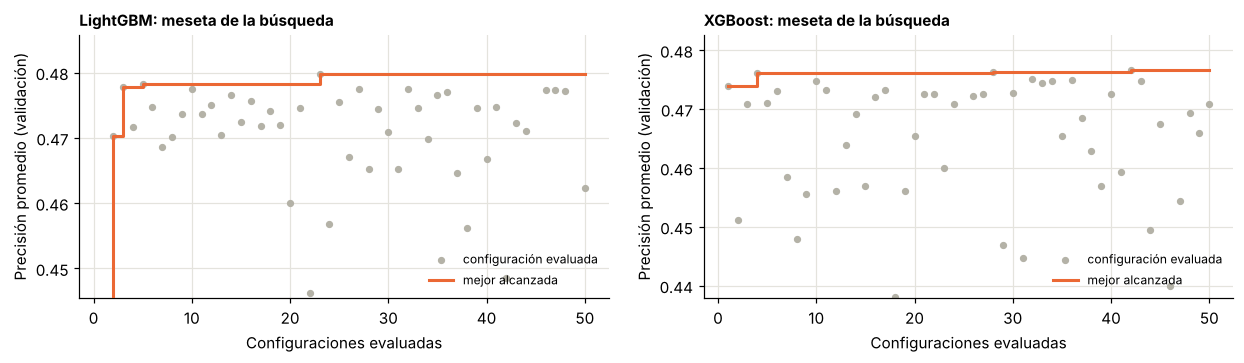

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4))
for ax, nombre in zip(axes, BUSQ_B):
    busq, _ = BUSQ_B[nombre]
    ap = busq.cv_results_["mean_test_score"]
    n = np.arange(1, len(ap) + 1)
    ax.scatter(n, ap, s=14, color="#b4b2a7", label="configuración evaluada", zorder=2)
    ax.step(n, np.maximum.accumulate(ap), where="post", color=COLOR_FAMILIA["boosting"], linewidth=2,
            label="mejor alcanzada", zorder=3)
    ax.set_ylim(np.quantile(ap, 0.1) - 0.01, ap.max() + 0.006)
    ax.set_xlabel("Configuraciones evaluadas")
    ax.set_ylabel("Precisión promedio (validación)")
    ax.legend(loc="lower right", fontsize=8, frameon=False)
    ax.set_title(f"{nombre}: meseta de la búsqueda", fontsize=10)
plt.tight_layout()
plt.show()

In [33]:
evaluar_b("LightGBM optimizado + umbral", con_umbral(lgbm_opt_b), "boosting", "umbral (+ pesos si los eligió)",
          config=config_lgbm_b, t_busqueda=t_lgbm_b)
evaluar_b("XGBoost optimizado + umbral", con_umbral(xgb_opt_b), "boosting", "umbral (+ pesos si los eligió)",
          config=config_xgb_b, t_busqueda=t_xgb_b)

LightGBM optimizado + umbral: F1 macro = 0.7207 ± 0.0059 · sens. yes = 0.547 · entrenamiento 15.1 s por pliegue
XGBoost optimizado + umbral: F1 macro = 0.7171 ± 0.0062 · sens. yes = 0.555 · entrenamiento 8.2 s por pliegue


### 11.5 Combinaciones

- **Votación suave** de los dos *boosting* optimizados y la regresión logística, con ajuste de umbral sobre la probabilidad promedio.
- ***Stacking*** de LightGBM, XGBoost, Random Forest y regresión logística. El umbral se ajusta **dentro del meta-modelo**: su entrada ya son predicciones fuera de pliegue de la validación cruzada interna de `StackingClassifier`, así que `TunedThresholdClassifierCV` sobre la regresión logística final es barato y no ve datos de validación.

In [34]:
miembros_b = [("lgbm", clone(lgbm_opt_b)), ("xgb", clone(xgb_opt_b)), ("rl", clone(rl_b))]
evaluar_b("Votación suave (LightGBM, XGBoost, RL) + umbral",
          con_umbral(VotingClassifier(miembros_b, voting="soft")), "combinación", "umbral")

stacking_b = StackingClassifier(
    miembros_b + [("rf", clone(rf_b))],
    final_estimator=TunedThresholdClassifierCV(LogisticRegression(max_iter=3000), scoring="f1_macro", cv=CV_UMBRAL),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_BANCO), stack_method="predict_proba")
evaluar_b("Stacking (LightGBM, XGBoost, RF, RL) + umbral en el meta-modelo", stacking_b, "combinación", "umbral")

Votación suave (LightGBM, XGBoost, RL) + umbral: F1 macro = 0.7176 ± 0.0058 · sens. yes = 0.540 · entrenamiento 24.0 s por pliegue
Stacking (LightGBM, XGBoost, RF, RL) + umbral en el meta-modelo: F1 macro = 0.7172 ± 0.0066 · sens. yes = 0.556 · entrenamiento 74.7 s por pliegue


## 12. Tabla de Bank Marketing, matriz de confusión y modelo final

In [35]:
filas = []
for nombre, r in RES_B.items():
    filas.append({"modelo": nombre, "familia": r["familia"], "balanceo": r["balanceo"],
                  "F1 macro": f"{r['f1'].mean():.3f} ± {r['f1'].std(ddof=1):.3f}", "_f1": r["f1"].mean(),
                  "sens. yes": r["sens"].mean(), "entrenamiento (s/pliegue)": r["t_fit"],
                  "búsqueda (s)": r["t_busqueda"]})
tabla_banco = pd.DataFrame(filas).sort_values("_f1", ascending=False).reset_index(drop=True)
tabla_banco.index = tabla_banco.index + 1
MEJOR_B = tabla_banco.loc[1, "modelo"]
display(tabla_banco.drop(columns="_f1").style.format(
    {"sens. yes": "{:.3f}", "entrenamiento (s/pliegue)": "{:.1f}", "búsqueda (s)": "{:.0f}"}, na_rep="—"))
print("Configuración de los modelos optimizados:")
for n in ["LightGBM optimizado + umbral", "XGBoost optimizado + umbral"]:
    print(f"  {n}: {RES_B[n]['config']}")

,modelo,familia,balanceo,F1 macro,sens. yes,entrenamiento (s/pliegue),búsqueda (s)
1,LightGBM optimizado + umbral,boosting,umbral (+ pesos si los eligió),0.721 ± 0.006,0.547,15.1,243
2,LightGBM + umbral,boosting,umbral,0.720 ± 0.007,0.530,8.9,—
3,Random Forest + umbral,bagging,umbral,0.719 ± 0.007,0.536,56.7,—
4,"Votación suave (LightGBM, XGBoost, RL) + umbral",combinación,umbral,0.718 ± 0.006,0.540,24.0,—
5,LightGBM (balanced) + umbral,boosting,pesos + umbral,0.717 ± 0.008,0.535,8.8,—
6,"Stacking (LightGBM, XGBoost, RF, RL) + umbral en el meta-modelo",combinación,umbral,0.717 ± 0.007,0.556,74.7,—
7,XGBoost optimizado + umbral,boosting,umbral (+ pesos si los eligió),0.717 ± 0.006,0.555,8.2,161
8,HistGradientBoosting + umbral,boosting,umbral,0.716 ± 0.007,0.551,4.4,—
9,Extra-Trees + umbral,bagging,umbral,0.716 ± 0.007,0.533,54.4,—
10,Árbol de decisión + umbral,individual,umbral,0.714 ± 0.006,0.554,1.7,—


Configuración de los modelos optimizados:
  LightGBM optimizado + umbral: class_weight = None, colsample_bytree = 0.424, learning_rate = 0.00685, max_depth = -1, min_child_samples = 29, n_estimators = 611, num_leaves = 44, reg_alpha = 0.00252, reg_lambda = 0.00302, subsample = 0.794
  XGBoost optimizado + umbral: colsample_bytree = 0.761, learning_rate = 0.00616, max_depth = 5, min_child_weight = 13.4, n_estimators = 680, reg_alpha = 0.00104, reg_lambda = 0.646, scale_pos_weight = 2.81, subsample = 0.841


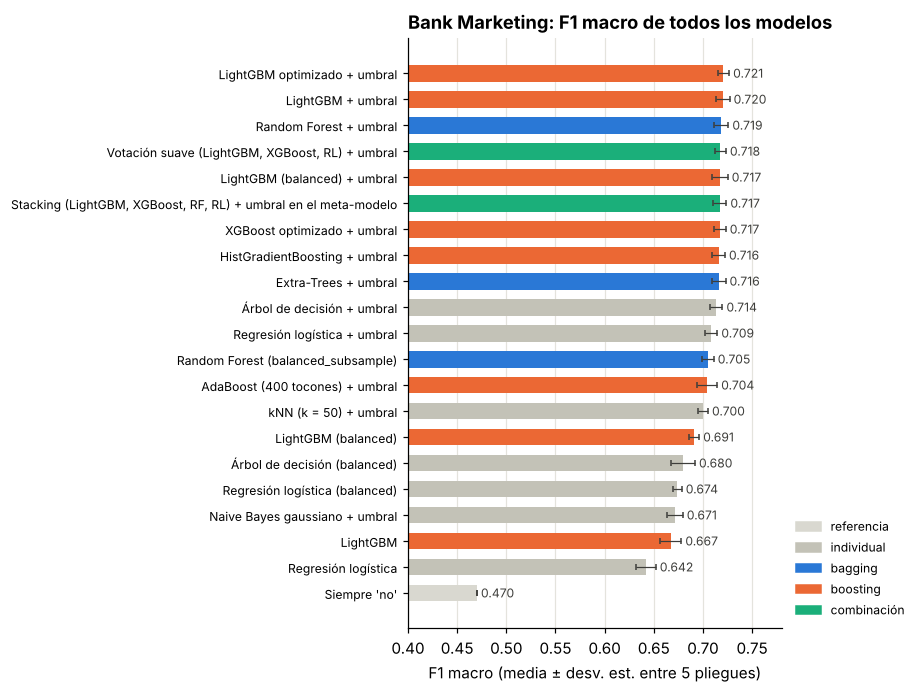

In [36]:
orden = tabla_banco["modelo"].tolist()[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6.4))
medias = [RES_B[n]["f1"].mean() for n in orden]
desv = [RES_B[n]["f1"].std(ddof=1) for n in orden]
ax.barh(range(len(orden)), medias, xerr=desv, height=0.65,
        color=[COLOR_FAMILIA[RES_B[n]["familia"]] for n in orden],
        error_kw=dict(ecolor="#3d3d3a", capsize=2, linewidth=0.8))
for i, (m_, s_) in enumerate(zip(medias, desv)):
    ax.text(m_ + s_ + 0.004, i, f"{m_:.3f}", va="center", fontsize=8, color="#3d3d3a")
ax.set_yticks(range(len(orden)), orden, fontsize=8)
ax.set_xlim(0.4, 0.78)
ax.set_xlabel("F1 macro (media ± desv. est. entre 5 pliegues)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=COLOR_FAMILIA[f], label=f) for f in
                   ["referencia", "individual", "bagging", "boosting", "combinación"]],
          loc="lower left", bbox_to_anchor=(1.01, 0.0), fontsize=8, frameon=False)
ax.set_title("Bank Marketing: F1 macro de todos los modelos")
plt.tight_layout()
plt.show()

### El umbral decide más que el modelo

Para ver por qué el ajuste del umbral domina, se toman las probabilidades fuera de pliegue del LightGBM optimizado (sin umbral) y se calcula el F1 macro que daría cada umbral.

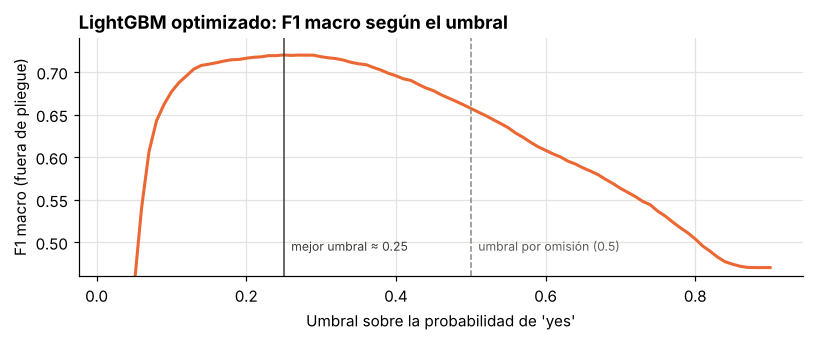

F1 macro con umbral 0.5: 0.6572; con el mejor umbral fijo (0.25): 0.7199


In [37]:
proba_oof_b = cross_val_predict(lgbm_opt_b, Xb, yb, cv=CV_B, method="predict_proba", n_jobs=N_JOBS)[:, 1]
umbrales = np.linspace(0.02, 0.9, 89)
f1_umbral = [f1_score(yb, (proba_oof_b >= u).astype(int), average="macro") for u in umbrales]
u_mejor = umbrales[int(np.argmax(f1_umbral))]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(umbrales, f1_umbral, color=COLOR_FAMILIA["boosting"], linewidth=2)
ax.axvline(0.5, color="#8a8980", linestyle="--", linewidth=1)
ax.text(0.51, 0.49, "umbral por omisión (0.5)", fontsize=8, color="#5f5e5a")
ax.axvline(u_mejor, color="#3d3d3a", linewidth=1)
ax.text(u_mejor + 0.01, 0.49, f"mejor umbral ≈ {u_mejor:.2f}", fontsize=8, color="#3d3d3a")
ax.set_ylim(0.46, 0.74)
ax.set_xlabel("Umbral sobre la probabilidad de 'yes'")
ax.set_ylabel("F1 macro (fuera de pliegue)")
ax.set_title("LightGBM optimizado: F1 macro según el umbral")
plt.tight_layout()
plt.show()
print(f"F1 macro con umbral 0.5: {f1_score(yb, (proba_oof_b >= 0.5).astype(int), average='macro'):.4f}; "
      f"con el mejor umbral fijo ({u_mejor:.2f}): {max(f1_umbral):.4f}")

### Matriz de confusión del mejor modelo

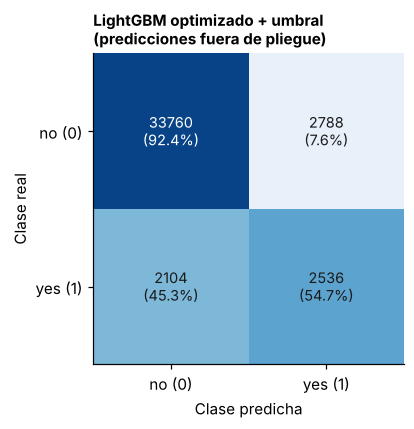

Sensibilidad de yes: 0.547 · precisión de yes: 0.476 · F1 de yes: 0.509 · F1 de no: 0.932


In [38]:
modelo_final_b = RES_B[MEJOR_B]["modelo"]
pred_b = cross_val_predict(modelo_final_b, Xb, yb, cv=CV_B, n_jobs=N_JOBS)
fig, ax = plt.subplots(figsize=(4.8, 4.0))
cm_b = matriz(ax, yb, pred_b, [0, 1], ["no (0)", "yes (1)"], f"{MEJOR_B}\n(predicciones fuera de pliegue)")
plt.tight_layout()
plt.show()
tn, fp, fn, tp = cm_b.ravel()
print(f"Sensibilidad de yes: {tp / (tp + fn):.3f} · precisión de yes: {tp / (tp + fp):.3f} · "
      f"F1 de yes: {f1_score(yb, pred_b):.3f} · F1 de no: {f1_score(yb, pred_b, pos_label=0):.3f}")

### Guardado del modelo final

El mejor modelo se entrena con los 41 188 clientes y se guarda con `joblib`. Se compone solo de clases de scikit-learn, LightGBM y XGBoost, así que el archivo se carga sin definir nada en el notebook. Como comprobación, se carga de nuevo y se evalúa con la instrucción exacta del enunciado (`cross_validate` lo clona y reentrena en cada pliegue).

In [39]:
SLUG = {"Stacking (LightGBM, XGBoost, RF, RL) + umbral en el meta-modelo": "stacking",
        "Votación suave (LightGBM, XGBoost, RL) + umbral": "votacion-suave",
        "LightGBM optimizado + umbral": "lightgbm", "XGBoost optimizado + umbral": "xgboost"}
ARCHIVO_MODELO = Path(f"{ESTUDIANTE}-{SLUG.get(MEJOR_B, re.sub(r'[^a-z0-9]+', '-', MEJOR_B.lower()).strip('-'))}.joblib")
t0 = time.perf_counter()
modelo_entrega = clone(modelo_final_b).fit(Xb, yb)
joblib.dump(modelo_entrega, ARCHIVO_MODELO, compress=3)
print(f"{MEJOR_B} entrenado con todo el conjunto en {time.perf_counter() - t0:.0f} s → {ARCHIVO_MODELO} "
      f"({ARCHIVO_MODELO.stat().st_size / 1e6:.1f} MB)")

modelo = joblib.load(ARCHIVO_MODELO)
X, y = Xb, yb          # nombres del enunciado
f1_enunciado = cross_validate(modelo, X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2026),
                              scoring="f1_macro", n_jobs=N_JOBS)["test_score"]
print(f"cross_validate(modelo, X, y, ...) → F1 macro = {f1_enunciado.mean():.4f} ± {f1_enunciado.std(ddof=1):.4f}")
assert np.allclose(f1_enunciado, RES_B[MEJOR_B]["f1"])

LightGBM optimizado + umbral entrenado con todo el conjunto en 17 s → marey-lugo-lightgbm.joblib (1.2 MB)
cross_validate(modelo, X, y, ...) → F1 macro = 0.7207 ± 0.0059


## 13. ¿Funcionó lo mismo que en la deserción, y por qué?

**Resultado.** El mejor modelo es **LightGBM optimizado con ajuste de umbral: F1 macro = 0.721 ± 0.006**, con sensibilidad de *yes* de 0.547. Pero nueve modelos de tres familias distintas quedan en un rango de 0.005 (de 0.716 a 0.721): LightGBM con valores por omisión y umbral (0.720), Random Forest con umbral (0.719), la votación suave (0.718), LightGBM con pesos y umbral, el *stacking* y XGBoost optimizado (0.717), HistGradientBoosting y Extra-Trees (0.716). Esa diferencia es menor que la desviación entre pliegues (≈ 0.006). En la matriz de confusión, el modelo encuentra al 54.7 % de los clientes que aceptan, y menos de la mitad de las llamadas que recomienda (47.6 %) terminan en *yes*. El F1 de *yes* es 0.51 y el de *no*, 0.93: el promedio, 0.72, lo limita la clase minoritaria.

**¿Funcionó lo mismo que en la deserción?** En parte. Hubo tres coincidencias y tres diferencias.

*Coincidencias:*

1. **Un *gradient boosting* optimizado quedó primero en los dos problemas, por márgenes mínimos.** En la deserción, XGBoost superó al SVM por 0.009; en Bank Marketing, LightGBM superó por 0.001 a su propia versión sin optimizar y por 0.002 a Random Forest. En los dos casos el margen es menor que la variación entre pliegues.
2. **Combinar no agregó nada.** La votación y el *stacking* no superaron a su mejor miembro en ninguno de los dos problemas. En la deserción, los dos mejores base tenían errores con correlación de 0.83. En Bank Marketing, LightGBM, XGBoost y Random Forest son árboles que aprenden los mismos cortes sobre los mismos indicadores económicos: sus probabilidades están muy correlacionadas y promediarlas no cambia casi ninguna decisión.
3. **Atender el desbalance pesó más que elegir el modelo.** Sin ningún ajuste, los modelos quedan muy abajo en los dos conjuntos. En la deserción, en las cuatro búsquedas, las configuraciones sin pesos por clase quedaron por debajo de las que sí los usaban (hasta 15 puntos en Random Forest). En Bank Marketing, la regresión logística pasa de 0.642 a 0.709 y LightGBM de 0.667 a 0.720 solo con el umbral.

*Diferencias:*

1. **En la deserción, un modelo lineal bien ajustado empataba con los ensambles; en Bank Marketing, no.** Aquí la regresión logística con umbral queda en 0.709, 0.012 por debajo del mejor, y hasta un solo árbol de profundidad 6 la supera (0.714). Tres características de los datos lo explican:
   - **Tamaño:** Bank Marketing tiene 12 veces más filas (41 188 frente a 3539) y menos atributos (19 frente a 30). Con 33 mil filas por partición, los modelos flexibles pueden aprender interacciones sin sobreajustar. La desviación entre pliegues, aproximadamente la mitad que en la deserción, es otra señal de que la varianza es baja.
   - **Forma de la señal:** en Bank Marketing, la señal está en umbrales e interacciones. Los indicadores económicos solo toman unas pocas combinaciones de valores, una por periodo de la campaña. El efecto de `month`, `poutcome` y `pdays` es escalonado, y la tasa de *yes* va de 6 % a 51 % según el mes. Un árbol representa eso con unos cuantos cortes; un modelo lineal necesita que se lo construyan. En la deserción, la señal principal era casi aditiva (unidades aprobadas, colegiatura al día) y la frontera, casi lineal (el SVM lineal estaba a 0.008 del polinomial).
2. **El mecanismo de balanceo que funciona es otro.** En la deserción, con tres clases y la predicción por la clase más probable, la herramienta eficaz fueron los **pesos por clase**. En Bank Marketing, que es binario, el **ajuste del umbral** gana claramente a los pesos: LightGBM obtiene 0.691 con pesos y 0.720 con umbral. Combinar ambos no suma (0.717). El umbral optimiza directamente la métrica con un solo parámetro, ajustado por validación cruzada interna. Los pesos, en cambio, cambian el entrenamiento y mueven el umbral implícito hacia un punto (sensibilidad ≈ 0.64) que no es el que maximiza el F1 macro. Con el umbral ya ajustado, los pesos sobran: la búsqueda de LightGBM, de hecho, eligió `class_weight = None`.
3. ***Bagging* rindió igual que *boosting*.** Random Forest con umbral (0.719) queda a 0.002 del mejor. En la deserción, Random Forest también quedó a 0.007 de XGBoost. Que ambas familias lleguen al mismo techo sugiere que el límite no está en el modelo sino en la información. Sin `duration`, lo que se sabe del cliente antes de llamar solo permite ordenar a los clientes, no separarlos: la precisión promedio del mejor modelo es apenas 0.48.

## 14. Conclusiones

**¿Qué aportó cada familia de ensambles?**

| Familia | Qué reduce | Deserción | Bank Marketing |
|---|---|---|---|
| ***Bagging* (y Random Forest, Extra-Trees)** | **Varianza**: promedia árboles inestables. Random Forest además decorrelaciona los árboles con `max_features` y `max_samples`. | Convirtió un árbol sin límite de 0.582 en 0.663 (*bagging*) y 0.684 (Random Forest con pesos). Empató al SVM, pero no lo superó. | Random Forest con umbral, 0.719: a 0.002 del mejor, y mejor que cualquier modelo individual. |
| ***Boosting* (AdaBoost, XGBoost, LightGBM)** | **Sesgo**: cada ronda corrige los errores del ensamble anterior. Las versiones modernas agregan tasa de aprendizaje, submuestreo y regularización para controlar también la varianza. | AdaBoost con tocones subió de 0.492 a 0.656 en 1000 rondas, pero no alcanzó a los base. XGBoost optimizado fue el mejor modelo (0.691, +0.009). | LightGBM optimizado fue el mejor (0.721). AdaBoost con tocones quedó en 0.704, por debajo de un solo árbol podado. |
| **Combinación (votación, *stacking*)** | Errores **no correlacionados** entre modelos distintos. | Votación dura +0.005, *stacking* +0.0005, votación suave −0.010: los errores de los base estaban muy correlacionados (φ = 0.52; 0.83 entre SVM y regresión logística). | Votación suave y *stacking* (0.718 y 0.717) quedaron por debajo de su mejor miembro: los tres modelos de árboles aprenden lo mismo. |

**Qué diferencias se observaron, y qué características de los datos las explican.**

- **Tamaño del conjunto y forma de la frontera.** Con pocos datos y una señal casi lineal (deserción), un modelo lineal regularizado y con pesos por clase ya extrae casi todo lo que hay, y los ensambles de árboles solo lo igualan. Con muchos datos, pocos atributos y una señal escalonada de umbrales e interacciones (Bank Marketing), los ensambles de árboles superan con claridad al modelo lineal.
- **Número de clases y tipo de desbalance.** En el problema de tres clases con desbalance moderado (deserción), lo que decidió el resultado fueron los pesos por clase. En el problema binario con 11 % de positivos (Bank Marketing), fue el umbral, que valió más que cualquier cambio de modelo: +0.06 de F1 macro para el mismo LightGBM.
- **Ruido irreducible.** Los dos problemas tienen un techo que no depende del clasificador. En la deserción, el 11.5 % de los estudiantes es mal clasificado por los cinco base, y la clase *inscrito* no se distingue con la información del primer semestre. En Bank Marketing, sin la duración de la llamada, nueve modelos de tres familias quedan en 0.716–0.721. Cuando el techo lo pone la información, los ensambles solo aportan el último punto porcentual.
- **Diversidad.** Los ensambles que combinan modelos solo ganan si los miembros se equivocan en casos distintos. En los dos problemas, los mejores modelos eran demasiado parecidos entre sí como para que la combinación aportara.

**En resumen:** los ensambles mejoran mucho a los modelos inestables o demasiado simples de los que parten (*bagging* sobre el árbol sin límite, *boosting* sobre el tocón). Sobre clasificadores ya bien ajustados, en cambio, ganan muy poco: +0.009 en la deserción y +0.012 sobre la regresión logística en Bank Marketing. Antes de recurrir a un ensamble, rinde más cuidar la regla de decisión (pesos o umbral) y el preprocesamiento. Cuando hay datos suficientes y la señal no es lineal, un *gradient boosting* bien regularizado es la opción más sólida.

### Referencias

- Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data*, 7(11), 146. https://doi.org/10.3390/data7110146
- Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, 62, 22–31. https://doi.org/10.1016/j.dss.2014.03.001